# Colorectal adenoma-carcinoma progression
Hiu Mai

I wanted to identify genes that change consistently as colorectal tissue progresses from normal tissue to adenoma and early carcinoma, then use those genes to prioritize polyphenols. I use [GSE228012](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE228012) for the expression analysis and archived compound-target records for the network analysis.

This notebook follows the analysis from the expression matrix to the compound ranking and docking scores. It accompanies my [submitted manuscript](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/manuscript/submitted-manuscript.pdf). The [repository](https://github.com/hiuuuuu33/colorectal-polyphenol-research) contains the inputs, original research files and source records.

[Expression analysis](#expression-analysis) · [Progression-associated genes](#progression-genes) · [Functional enrichment](#functional-enrichment) · [Protein network](#protein-network) · [Polyphenol prioritization](#polyphenol-prioritization) · [Docking](#docking) · [Checks and references](#checks-and-references)

## Setup
I load the plotting packages and the functions used to read the archived results. The expression model and plotting steps are written out below. All data paths are relative to the repository folder.

In [1]:
root <- normalizePath(Sys.getenv("RESEARCH_REPO_ROOT", unset = getwd()), mustWork = TRUE)
stopifnot(file.exists(file.path(root, "data", "transcriptomics")))
setwd(root)
python <- Sys.getenv("PYTHON", unset = Sys.which("python3"))
if (!nzchar(python)) stop("Python 3 is required; set PYTHON to its executable.")
library(limma)
library(ggplot2)
library(ggrepel)
library(patchwork)
source("scripts/R/01_transcriptomics.R")
source("scripts/R/02_enrichment_figures.R")
source("scripts/R/04_docking.R")
options(repr.plot.width = 12, repr.plot.height = 9, repr.plot.res = 150,
        jupyter.plot_mimetypes = "image/png", warn = 1)
set.seed(20261104)
show_table <- function(data, caption = NULL, digits = 3) {
  IRdisplay::display_html(as.character(knitr::kable(data, format = "html", row.names = FALSE,
                                                   caption = caption, digits = digits)))
}
stage_colors <- c(Normal = "#00A087", Adenoma = "#E64B35", CRC = "#3C5488")
plot_theme <- theme_bw(base_size = 12) +
  theme(plot.title = element_text(face = "bold"), legend.title = element_blank())

<a id="expression-analysis"></a>
## Expression analysis
GSE228012 contains 33 samples, with 11 samples in each tissue group. I begin with the processed FPKM matrix. For repeated gene symbols, I retain the row with the highest mean expression, then recover the tissue labels from the sample names.

In [2]:
raw <- read.delim("data/transcriptomics/GSE228012_all.gene.FPKM.mRNA_processed.txt",
                  check.names = TRUE)
symbols <- as.character(raw[[2]])
fpkm <- as.matrix(raw[, -(1:2)])
storage.mode(fpkm) <- "double"
ranked <- order(rowMeans(fpkm), decreasing = TRUE)
retained <- ranked[!duplicated(symbols[ranked])]
fpkm <- fpkm[retained, , drop = FALSE]
rownames(fpkm) <- symbols[retained]
colnames(fpkm) <- trimws(sub("\\.FPKM$", "", colnames(fpkm)))
group <- ifelse(grepl("T$", colnames(fpkm)), "CRC",
                 ifelse(grepl("N$", colnames(fpkm)), "Normal",
                        ifelse(grepl("pre$", colnames(fpkm)), "Adenoma", NA_character_)))
stopifnot(!anyNA(group))
group <- factor(group, levels = c("Normal", "Adenoma", "CRC"))
sample_info <- data.frame(sample = colnames(fpkm), group = group)
show_table(as.data.frame(table(group)), "Samples in each tissue group")

group,Freq
Normal,11
Adenoma,11
CRC,11


I keep genes with FPKM > 1 in at least seven samples, using the original filter `round(0.2 * 33)`. I then apply log2(FPKM + 1). This leaves 12,298 genes for the expression comparisons.

In [3]:
keep <- rowSums(fpkm > 1) >= round(0.2 * ncol(fpkm))
log2_fpkm <- log2(fpkm[keep, , drop = FALSE] + 1)
preprocessing <- data.frame(
  step = c("Input rows", "Unique gene symbols", "Genes after filtering", "Samples"),
  value = c(nrow(raw), nrow(fpkm), nrow(log2_fpkm), ncol(log2_fpkm))
)
show_table(preprocessing, "Expression preprocessing")

step,value
Input rows,18116
Unique gene symbols,18114
Genes after filtering,12298
Samples,33


### Differential expression
I fit the original three-group limma model and compare adenoma with normal tissue, carcinoma with adenoma, and carcinoma with normal tissue. I use Benjamini-Hochberg adjusted P < 0.05 and absolute log2 fold change > 1 to select differentially expressed genes.

In [4]:
design <- model.matrix(~0 + group)
colnames(design) <- levels(group)
contrasts <- makeContrasts(
  Adenoma_vs_Normal = Adenoma - Normal,
  CRC_vs_Adenoma = CRC - Adenoma,
  CRC_vs_Normal = CRC - Normal, levels = design
)
fit <- eBayes(contrasts.fit(lmFit(log2_fpkm, design), contrasts))
de <- lapply(colnames(contrasts), function(contrast) {
  dat <- topTable(fit, coef = contrast, number = Inf, adjust.method = "BH")
  dat$gene <- rownames(dat)
  dat <- dat[, c("gene", setdiff(names(dat), "gene"))]
  dat$direction <- ifelse(dat$adj.P.Val < 0.05 & dat$logFC > 1, "Up",
                          ifelse(dat$adj.P.Val < 0.05 & dat$logFC < -1, "Down", "Stable"))
  dat
})
names(de) <- colnames(contrasts)
de_summary <- do.call(rbind, lapply(names(de), function(contrast) {
  dat <- de[[contrast]]
  data.frame(contrast = contrast, tested = nrow(dat),
             significant = sum(dat$direction != "Stable"),
             up = sum(dat$direction == "Up"), down = sum(dat$direction == "Down"))
}))
show_table(de_summary, "Differential-expression results")

contrast,tested,significant,up,down
Adenoma_vs_Normal,12298,725,254,471
CRC_vs_Adenoma,12298,312,178,134
CRC_vs_Normal,12298,1544,855,689


### PCA and volcano plots
I use PCA to examine variation across the samples. Each gene is centered and scaled to unit variance, following the original analysis. The first two components account for 25.6% and 11.6% of the variance.

In [5]:
pca <- prcomp(t(log2_fpkm), center = TRUE, scale. = TRUE)
variance <- 100 * pca$sdev^2 / sum(pca$sdev^2)
pc <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2], group = group)
pca_plot <- ggplot(pc, aes(PC1, PC2, color = group, shape = group)) +
  stat_ellipse(type = "norm", linewidth = 0.5, show.legend = FALSE) +
  geom_point(size = 3) + scale_color_manual(values = stage_colors) +
  labs(title = "PCA of GSE228012",
       x = sprintf("PC1 (%.1f%%)", variance[1]),
       y = sprintf("PC2 (%.1f%%)", variance[2])) + plot_theme
show_table(data.frame(component = c("PC1", "PC2"), variance_percent = variance[1:2]),
           "Variance explained by the first two components", digits = 1)

component,variance_percent
PC1,25.6
PC2,11.6


The volcano plots place the size of each expression change against its adjusted P value. I combine them with the PCA plot to reproduce Figure 1.

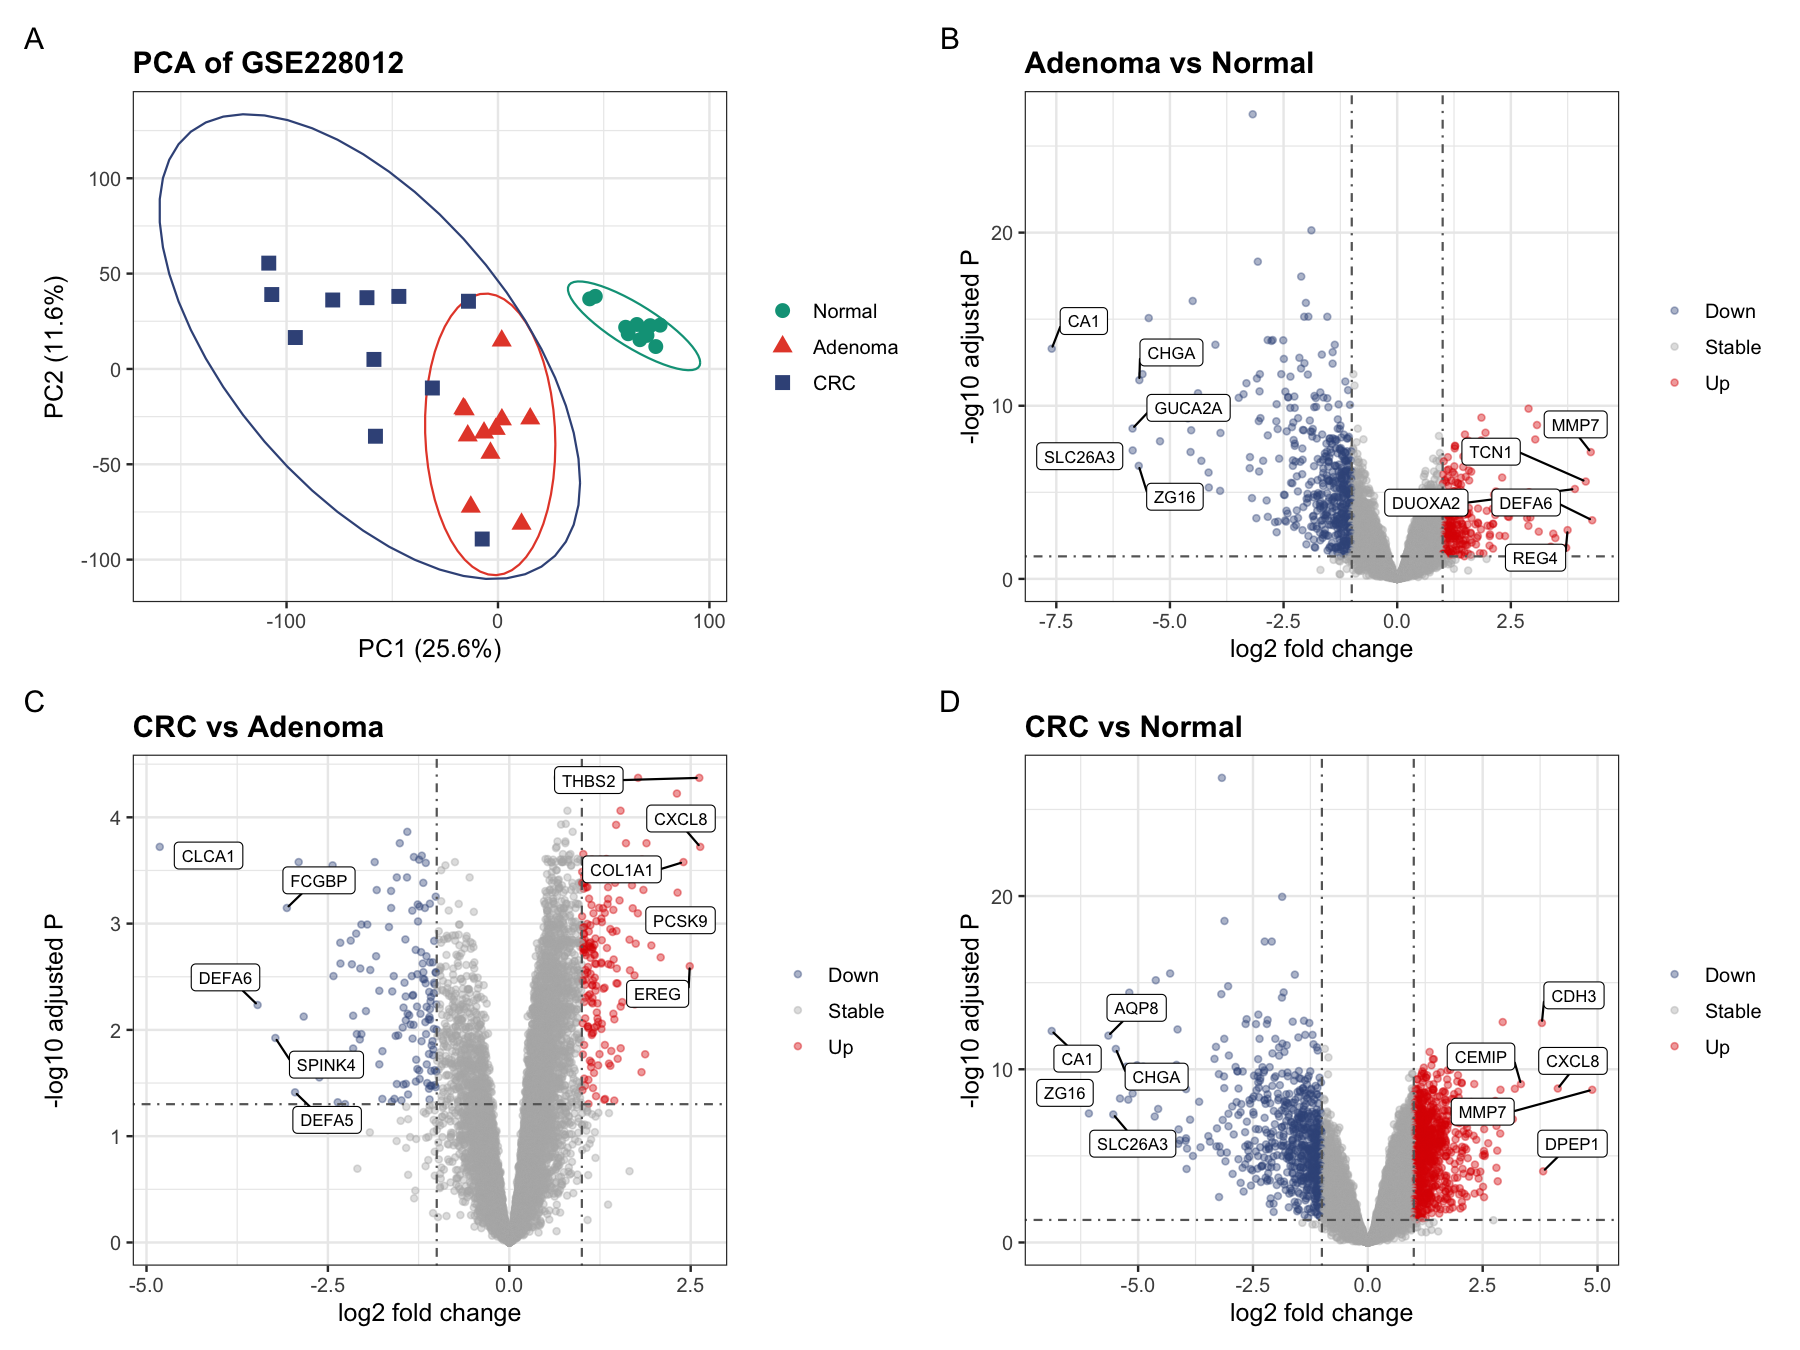

In [6]:
options(repr.plot.width = 12, repr.plot.height = 9)
volcano_plots <- lapply(names(de), function(contrast) {
  dat <- de[[contrast]]
  dat$neg_log10_adjP <- -log10(pmax(dat$adj.P.Val, .Machine$double.xmin))
  upper <- dat[dat$direction == "Up", ]
  lower <- dat[dat$direction == "Down", ]
  labels <- rbind(head(upper[order(-upper$logFC), ], 5),
                  head(lower[order(lower$logFC), ], 5))
  ggplot(dat, aes(logFC, neg_log10_adjP)) +
    geom_point(aes(color = direction), alpha = 0.4, size = 1.2) +
    scale_color_manual(values = c(Up = "#DC0000", Down = "#3C5488", Stable = "grey70")) +
    geom_vline(xintercept = c(-1, 1), linetype = 4, color = "grey40", linewidth = 0.5) +
    geom_hline(yintercept = -log10(0.05), linetype = 4, color = "grey40", linewidth = 0.5) +
    geom_label_repel(data = labels, aes(label = gene), seed = 20261104,
                     color = "black", size = 2.8, max.overlaps = Inf, box.padding = 0.4) +
    labs(title = gsub("_", " ", contrast),
         x = "log2 fold change", y = "-log10 adjusted P") + plot_theme
})
figure1 <- wrap_plots(c(list(pca_plot), volcano_plots), ncol = 2) +
  plot_annotation(tag_levels = "A")
figure1

<a id="progression-genes"></a>
## Progression-associated genes
I next look for genes that change in the same direction across both sequential comparisons. I intersect the upregulated genes in adenoma versus normal and carcinoma versus adenoma, and repeat this for the downregulated genes. The result contains eight up/up genes and 21 down/down genes.

In [7]:
na <- de$Adenoma_vs_Normal
ac <- de$CRC_vs_Adenoma
nc <- de$CRC_vs_Normal
up <- intersect(na$gene[na$direction == "Up"], ac$gene[ac$direction == "Up"])
down <- intersect(na$gene[na$direction == "Down"], ac$gene[ac$direction == "Down"])
build_progressive <- function(genes, direction) {
  data.frame(gene = genes,
             logFC_NA = na$logFC[match(genes, na$gene)],
             adjP_NA = na$adj.P.Val[match(genes, na$gene)],
             logFC_AC = ac$logFC[match(genes, ac$gene)],
             adjP_AC = ac$adj.P.Val[match(genes, ac$gene)],
             logFC_NC = nc$logFC[match(genes, nc$gene)],
             adjP_NC = nc$adj.P.Val[match(genes, nc$gene)], direction = direction)
}
prog <- rbind(build_progressive(up, "Up-Up"), build_progressive(down, "Down-Down"))
show_table(prog[, c("gene", "direction", "logFC_NA", "logFC_AC", "logFC_NC")],
           "The 29 progression-associated genes")

gene,direction,logFC_NA,logFC_AC,logFC_NC
TNFRSF12A,Up-Up,1.424,1.608,3.033
HIST3H2A,Up-Up,1.134,1.119,2.253
SLCO4A1,Up-Up,1.168,1.033,2.201
MYC,Up-Up,1.108,1.195,2.303
COL12A1,Up-Up,1.328,1.033,2.361
CXCL8,Up-Up,1.503,2.632,4.135
SLC22A3,Up-Up,1.091,1.032,2.123
CXCL2,Up-Up,1.139,1.405,2.545
CHP2,Down-Down,-3.239,-1.107,-4.346
TNFRSF17,Down-Down,-1.694,-1.059,-2.753


### Heatmap and expression trajectories
For the heatmap, I standardize each gene across samples so that genes with different expression levels can be compared. The columns follow the normal-adenoma-carcinoma order; the rows are clustered.

In [8]:
stage_order <- order(group)
heat <- log2_fpkm[prog$gene, stage_order, drop = FALSE]
heat_z <- t(scale(t(heat)))
col_anno <- data.frame(Stage = group[stage_order], row.names = colnames(heat))
row_anno <- data.frame(Direction = prog$direction, row.names = prog$gene)
heatmap <- pheatmap::pheatmap(
  heat_z, silent = TRUE, cluster_cols = FALSE, cluster_rows = TRUE,
  show_colnames = FALSE, fontsize_row = 8, annotation_col = col_anno,
  annotation_row = row_anno,
  annotation_colors = list(Stage = stage_colors,
                            Direction = c("Up-Up" = "#DC0000", "Down-Down" = "#3C5488")),
  gaps_col = c(11, 22), main = "29 progression-associated genes"
)

I calculate the mean log-transformed expression in each tissue group to draw the trajectories. The first eight rows below show the values used for the up/up genes.

In [9]:
means <- data.frame(
  gene = prog$gene, direction = prog$direction,
  Normal = rowMeans(log2_fpkm[prog$gene, group == "Normal", drop = FALSE]),
  Adenoma = rowMeans(log2_fpkm[prog$gene, group == "Adenoma", drop = FALSE]),
  CRC = rowMeans(log2_fpkm[prog$gene, group == "CRC", drop = FALSE])
)
long <- reshape(means, varying = c("Normal", "Adenoma", "CRC"), v.names = "Expression",
                 timevar = "Stage", times = c("Normal", "Adenoma", "CRC"), direction = "long")
long$Stage <- factor(long$Stage, levels = levels(group))
show_table(head(means, 8), "Mean expression by tissue group")

gene,direction,Normal,Adenoma,CRC
TNFRSF12A,Up-Up,2.527,3.952,5.560
HIST3H2A,Up-Up,2.776,3.910,5.029
SLCO4A1,Up-Up,0.892,2.061,3.093
MYC,Up-Up,3.893,5.001,6.196
COL12A1,Up-Up,1.988,3.316,4.349
CXCL8,Up-Up,1.454,2.957,5.589
SLC22A3,Up-Up,0.448,1.540,2.572
CXCL2,Up-Up,2.051,3.190,4.596


Figure 2 combines the 29-gene heatmap with the trajectories. I show the 15 down/down genes with the largest overall changes and all eight up/up genes, matching the original plotting selection.

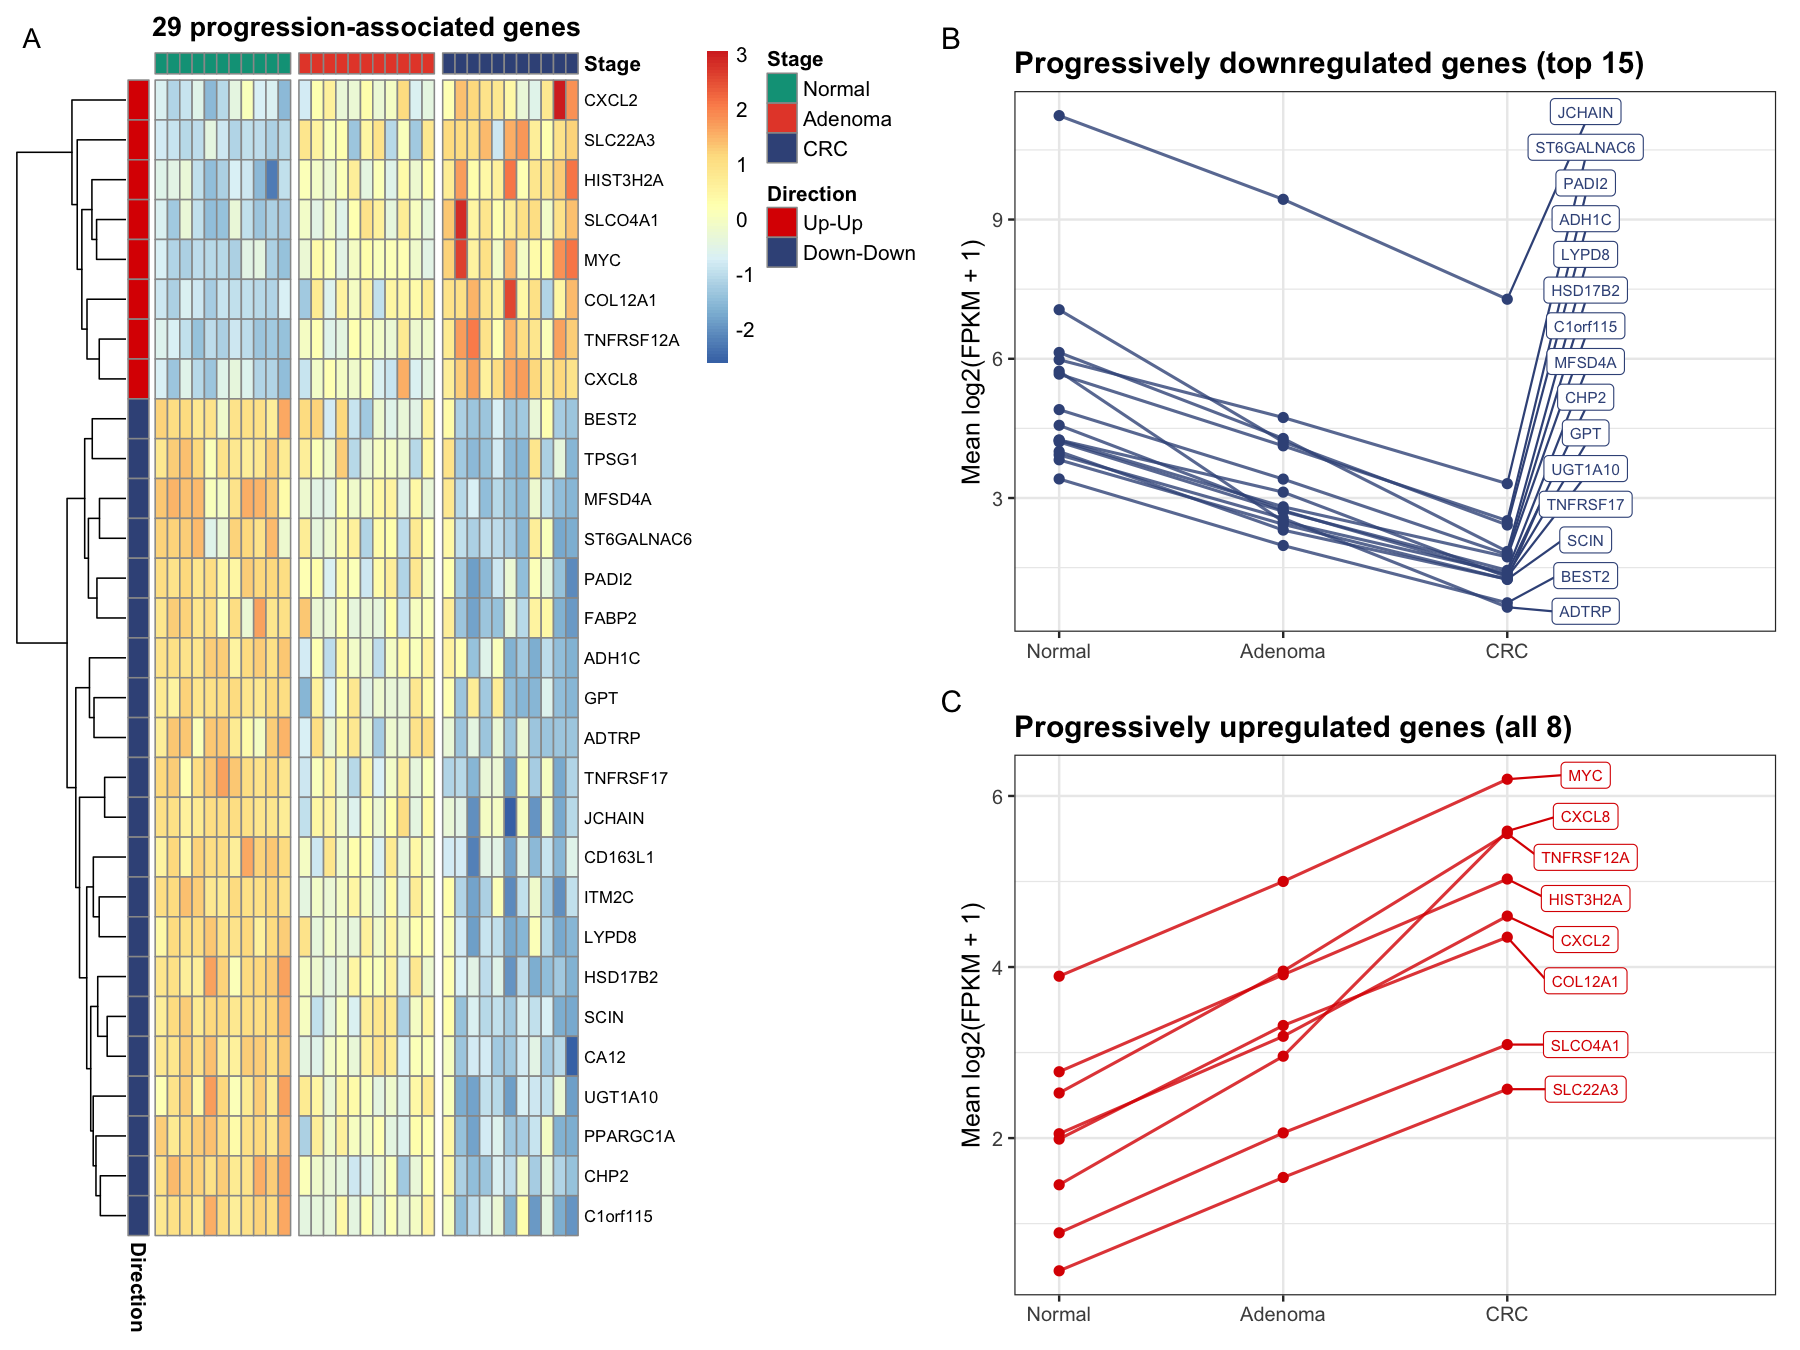

In [10]:
options(repr.plot.width = 12, repr.plot.height = 9)
line_plot <- function(direction, color, title) {
  chosen <- prog[prog$direction == direction, ]
  chosen <- head(chosen[order(-abs(chosen$logFC_NC)), "gene"], 15)
  dat <- long[long$gene %in% chosen, ]
  ggplot(dat, aes(Stage, Expression, group = gene)) +
    geom_line(color = color, linewidth = 0.7, alpha = 0.8) +
    geom_point(color = color, size = 1.8) +
    geom_label_repel(data = dat[dat$Stage == "CRC", ], aes(label = gene),
                     seed = 20261104, direction = "y", nudge_x = 0.35,
                     max.overlaps = Inf, size = 2.6, color = color) +
    scale_x_discrete(expand = expansion(add = c(0.2, 1.2))) +
    labs(title = title, x = NULL, y = "Mean log2(FPKM + 1)") + plot_theme
}
down_plot <- line_plot("Down-Down", "#3C5488", "Progressively downregulated genes (top 15)")
up_plot <- line_plot("Up-Up", "#DC0000", "Progressively upregulated genes (all 8)")
figure2 <- wrap_plots(wrap_elements(full = heatmap$gtable), down_plot, up_plot,
                      design = "AB\nAC", widths = c(1.15, 1)) +
  plot_annotation(tag_levels = "A")
figure2

<a id="functional-enrichment"></a>
## Functional enrichment
I use the complete GO and KEGG result tables saved with the project. The summary below counts the terms retained at adjusted P < 0.05 in each comparison. These are the original enrichment statistics; the following cells redraw their figures.

In [11]:
enrichment <- run_enrichment_figures(root)
show_table(enrichment$summary, "Archived enrichment results")

Enrichment figures complete: 15 frozen tables read; submitted significant-term counts verified.



contrast,category,tested_terms,significant_terms,source_mode
Adenoma_vs_Normal,GO_BP,4540,239,frozen_original_results
Adenoma_vs_Normal,GO_CC,381,21,frozen_original_results
Adenoma_vs_Normal,GO_MF,766,68,frozen_original_results
Adenoma_vs_Normal,KEGG_up,211,10,frozen_original_results
Adenoma_vs_Normal,KEGG_down,283,7,frozen_original_results
CRC_vs_Adenoma,GO_BP,3394,93,frozen_original_results
CRC_vs_Adenoma,GO_CC,322,19,frozen_original_results
CRC_vs_Adenoma,GO_MF,563,13,frozen_original_results
CRC_vs_Adenoma,KEGG_up,180,14,frozen_original_results
CRC_vs_Adenoma,KEGG_down,168,1,frozen_original_results


I plot up to 15 significant terms in each panel, ordered by gene ratio. Point size gives the gene count and color gives the adjusted P value. The same function is used for both sequential comparisons.

In [12]:
plot_enrichment <- function(contrast) {
  categories <- c("GO_BP", "GO_CC", "GO_MF", "KEGG_up", "KEGG_down")
  plots <- lapply(categories, function(category) {
    dat <- enrichment$results[[paste(contrast, category, sep = "__")]]
    significant <- dat[dat$p.adjust < 0.05, , drop = FALSE]
    shown <- head(significant[order(significant$p.adjust, significant$pvalue), ], 15)
    ratios <- strsplit(shown$GeneRatio, "/", fixed = TRUE)
    shown$GeneRatio_numeric <- vapply(ratios, function(x) as.numeric(x[1]) / as.numeric(x[2]), numeric(1))
    shown <- shown[order(shown$GeneRatio_numeric), ]
    shown$label <- vapply(shown$Description,
                          function(x) paste(strwrap(x, width = 42), collapse = "\n"), character(1))
    shown$label <- factor(shown$label, levels = unique(shown$label))
    ggplot(shown, aes(GeneRatio_numeric, label)) +
      geom_point(aes(size = Count, color = p.adjust)) +
      scale_color_gradient(low = "#CB2525", high = "#2866B0", name = "Adjusted P") +
      scale_size_continuous(range = c(3, 9), name = "Gene count") +
      labs(title = gsub("_", " ", category), subtitle = gsub("_", " ", contrast),
           x = "Gene ratio", y = NULL) +
      theme_bw(base_size = 11) +
      theme(plot.title = element_text(face = "bold"),
             axis.text.y = element_text(size = 9), panel.grid.minor = element_blank())
  })
  wrap_plots(plots, ncol = 2) + plot_annotation(tag_levels = "A")
}

### Adenoma versus normal tissue
Figure 3 shows the biological processes, cellular components, molecular functions and KEGG pathways in the adenoma-normal comparison.

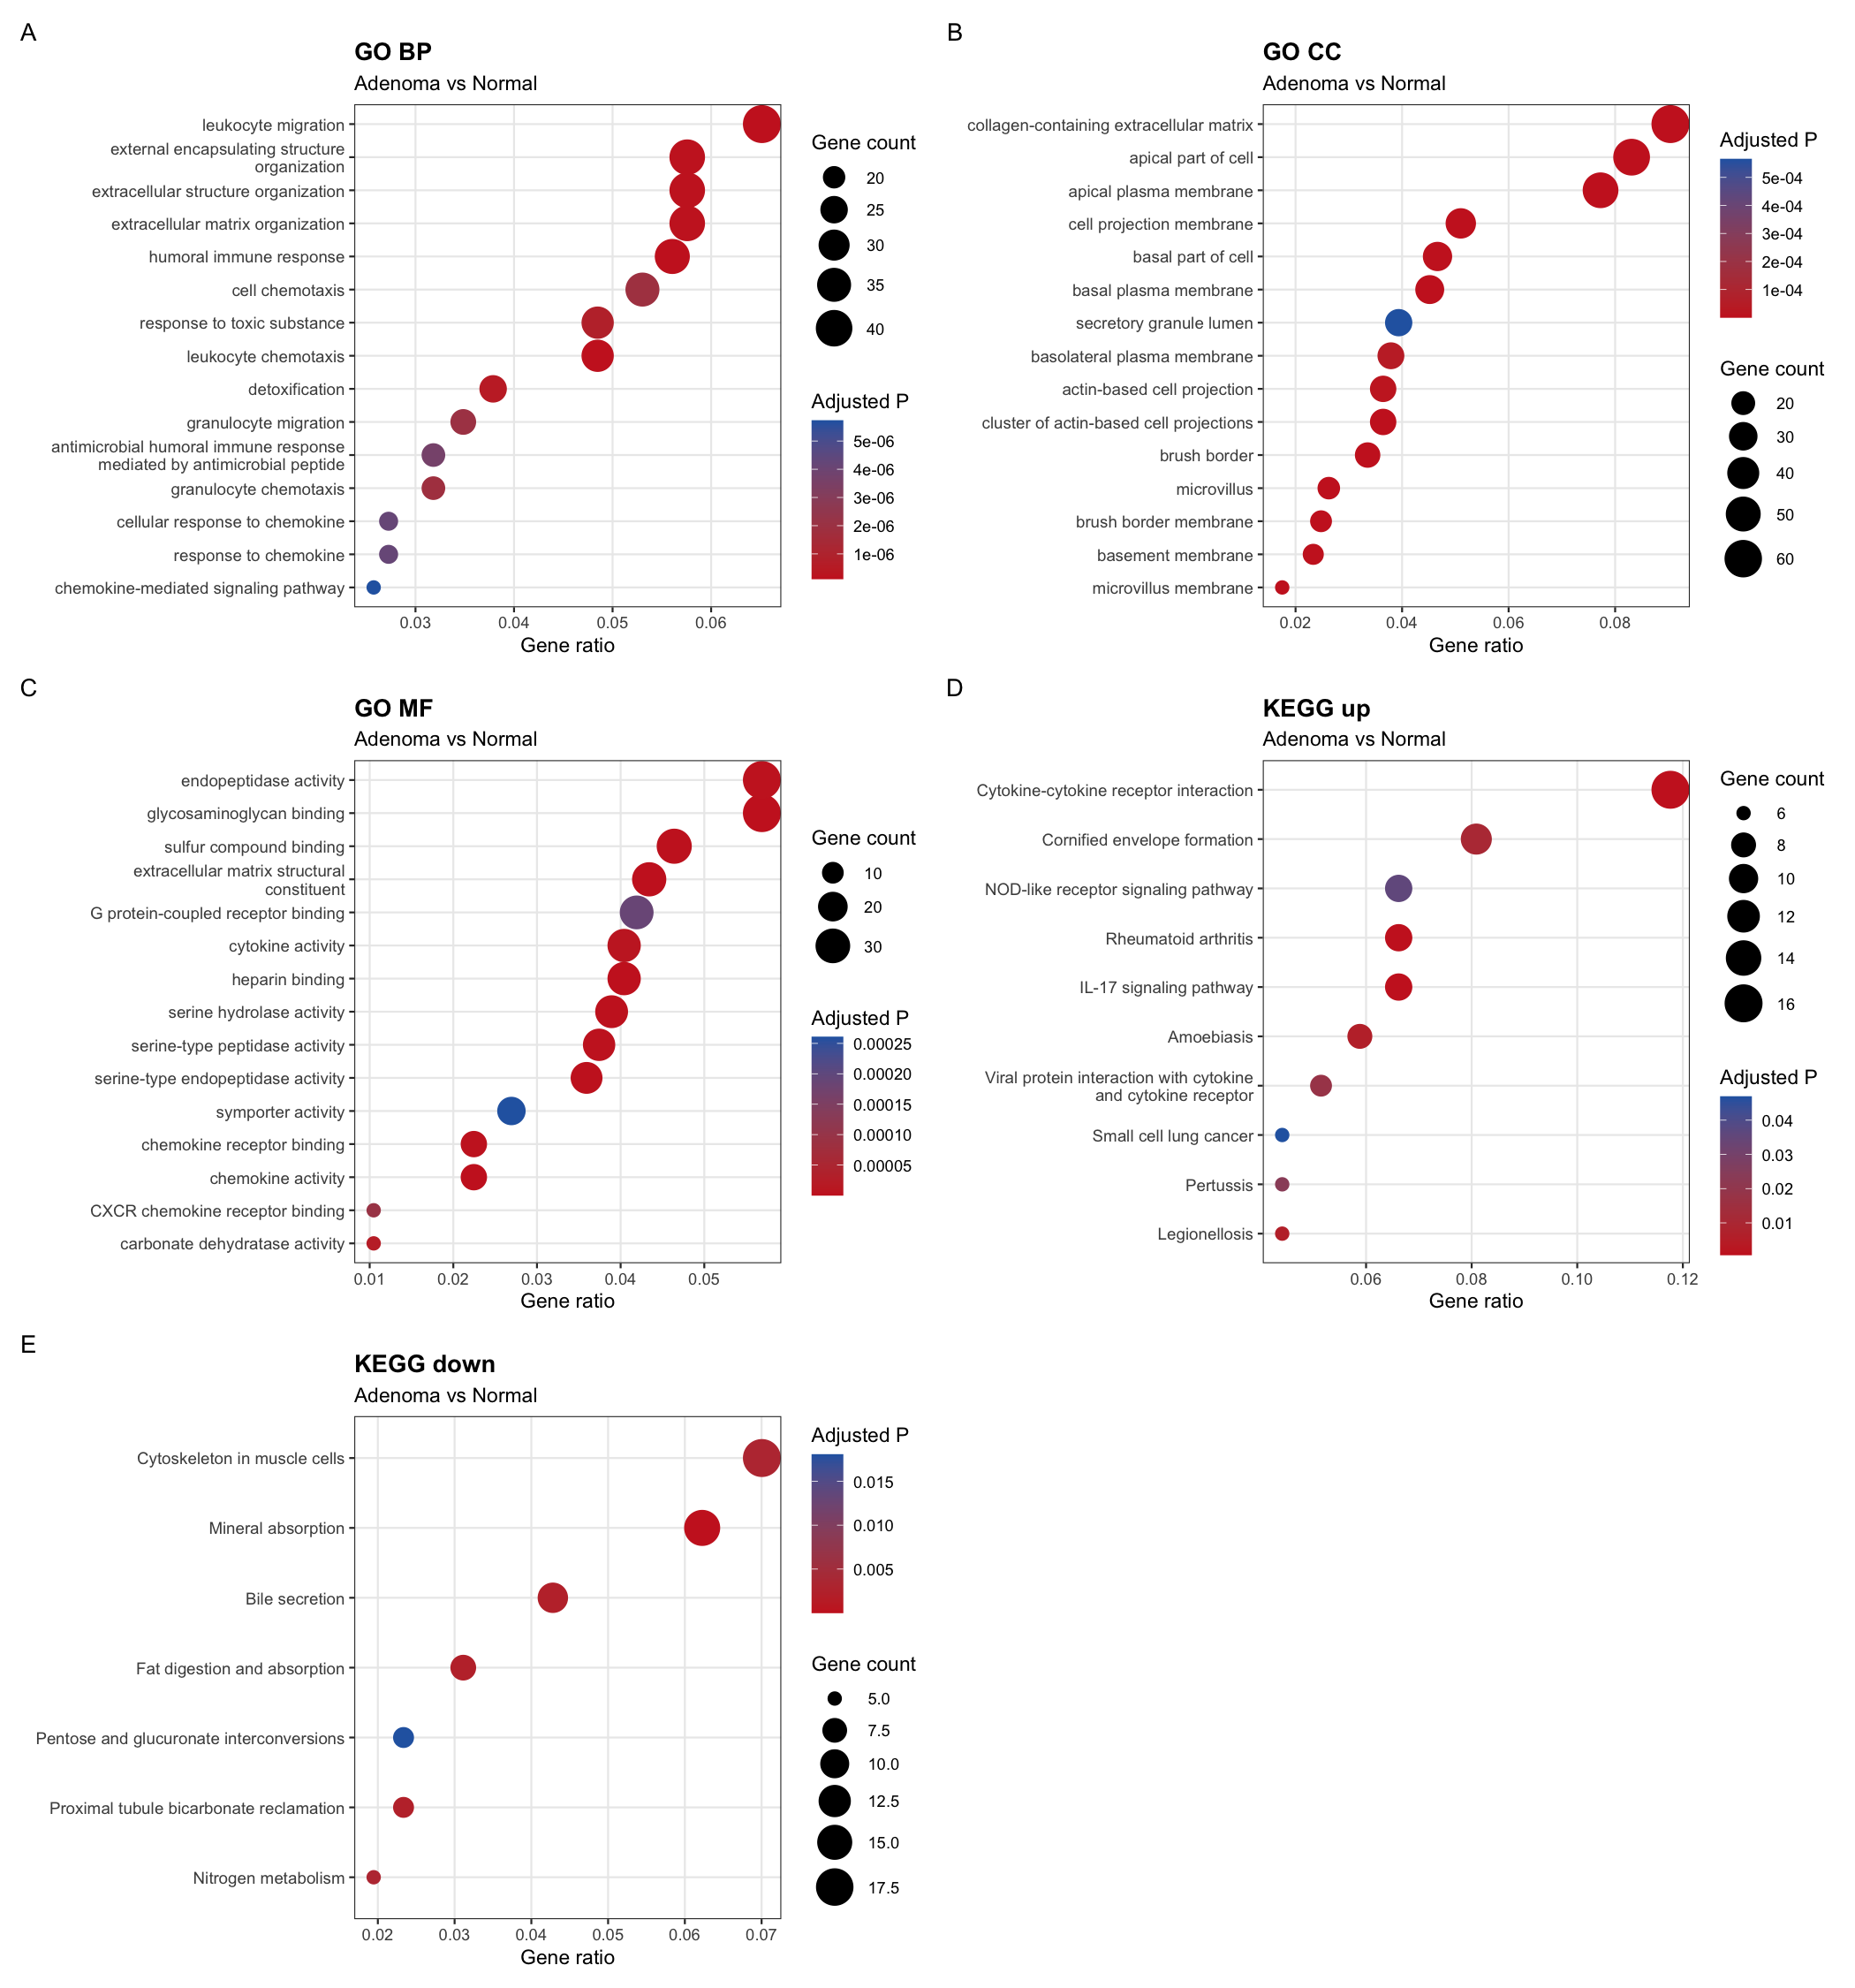

In [13]:
options(repr.plot.width = 14, repr.plot.height = 15)
plot_enrichment("Adenoma_vs_Normal")

### Carcinoma versus adenoma
I apply the same plotting rules to the carcinoma-adenoma comparison for Figure 4.

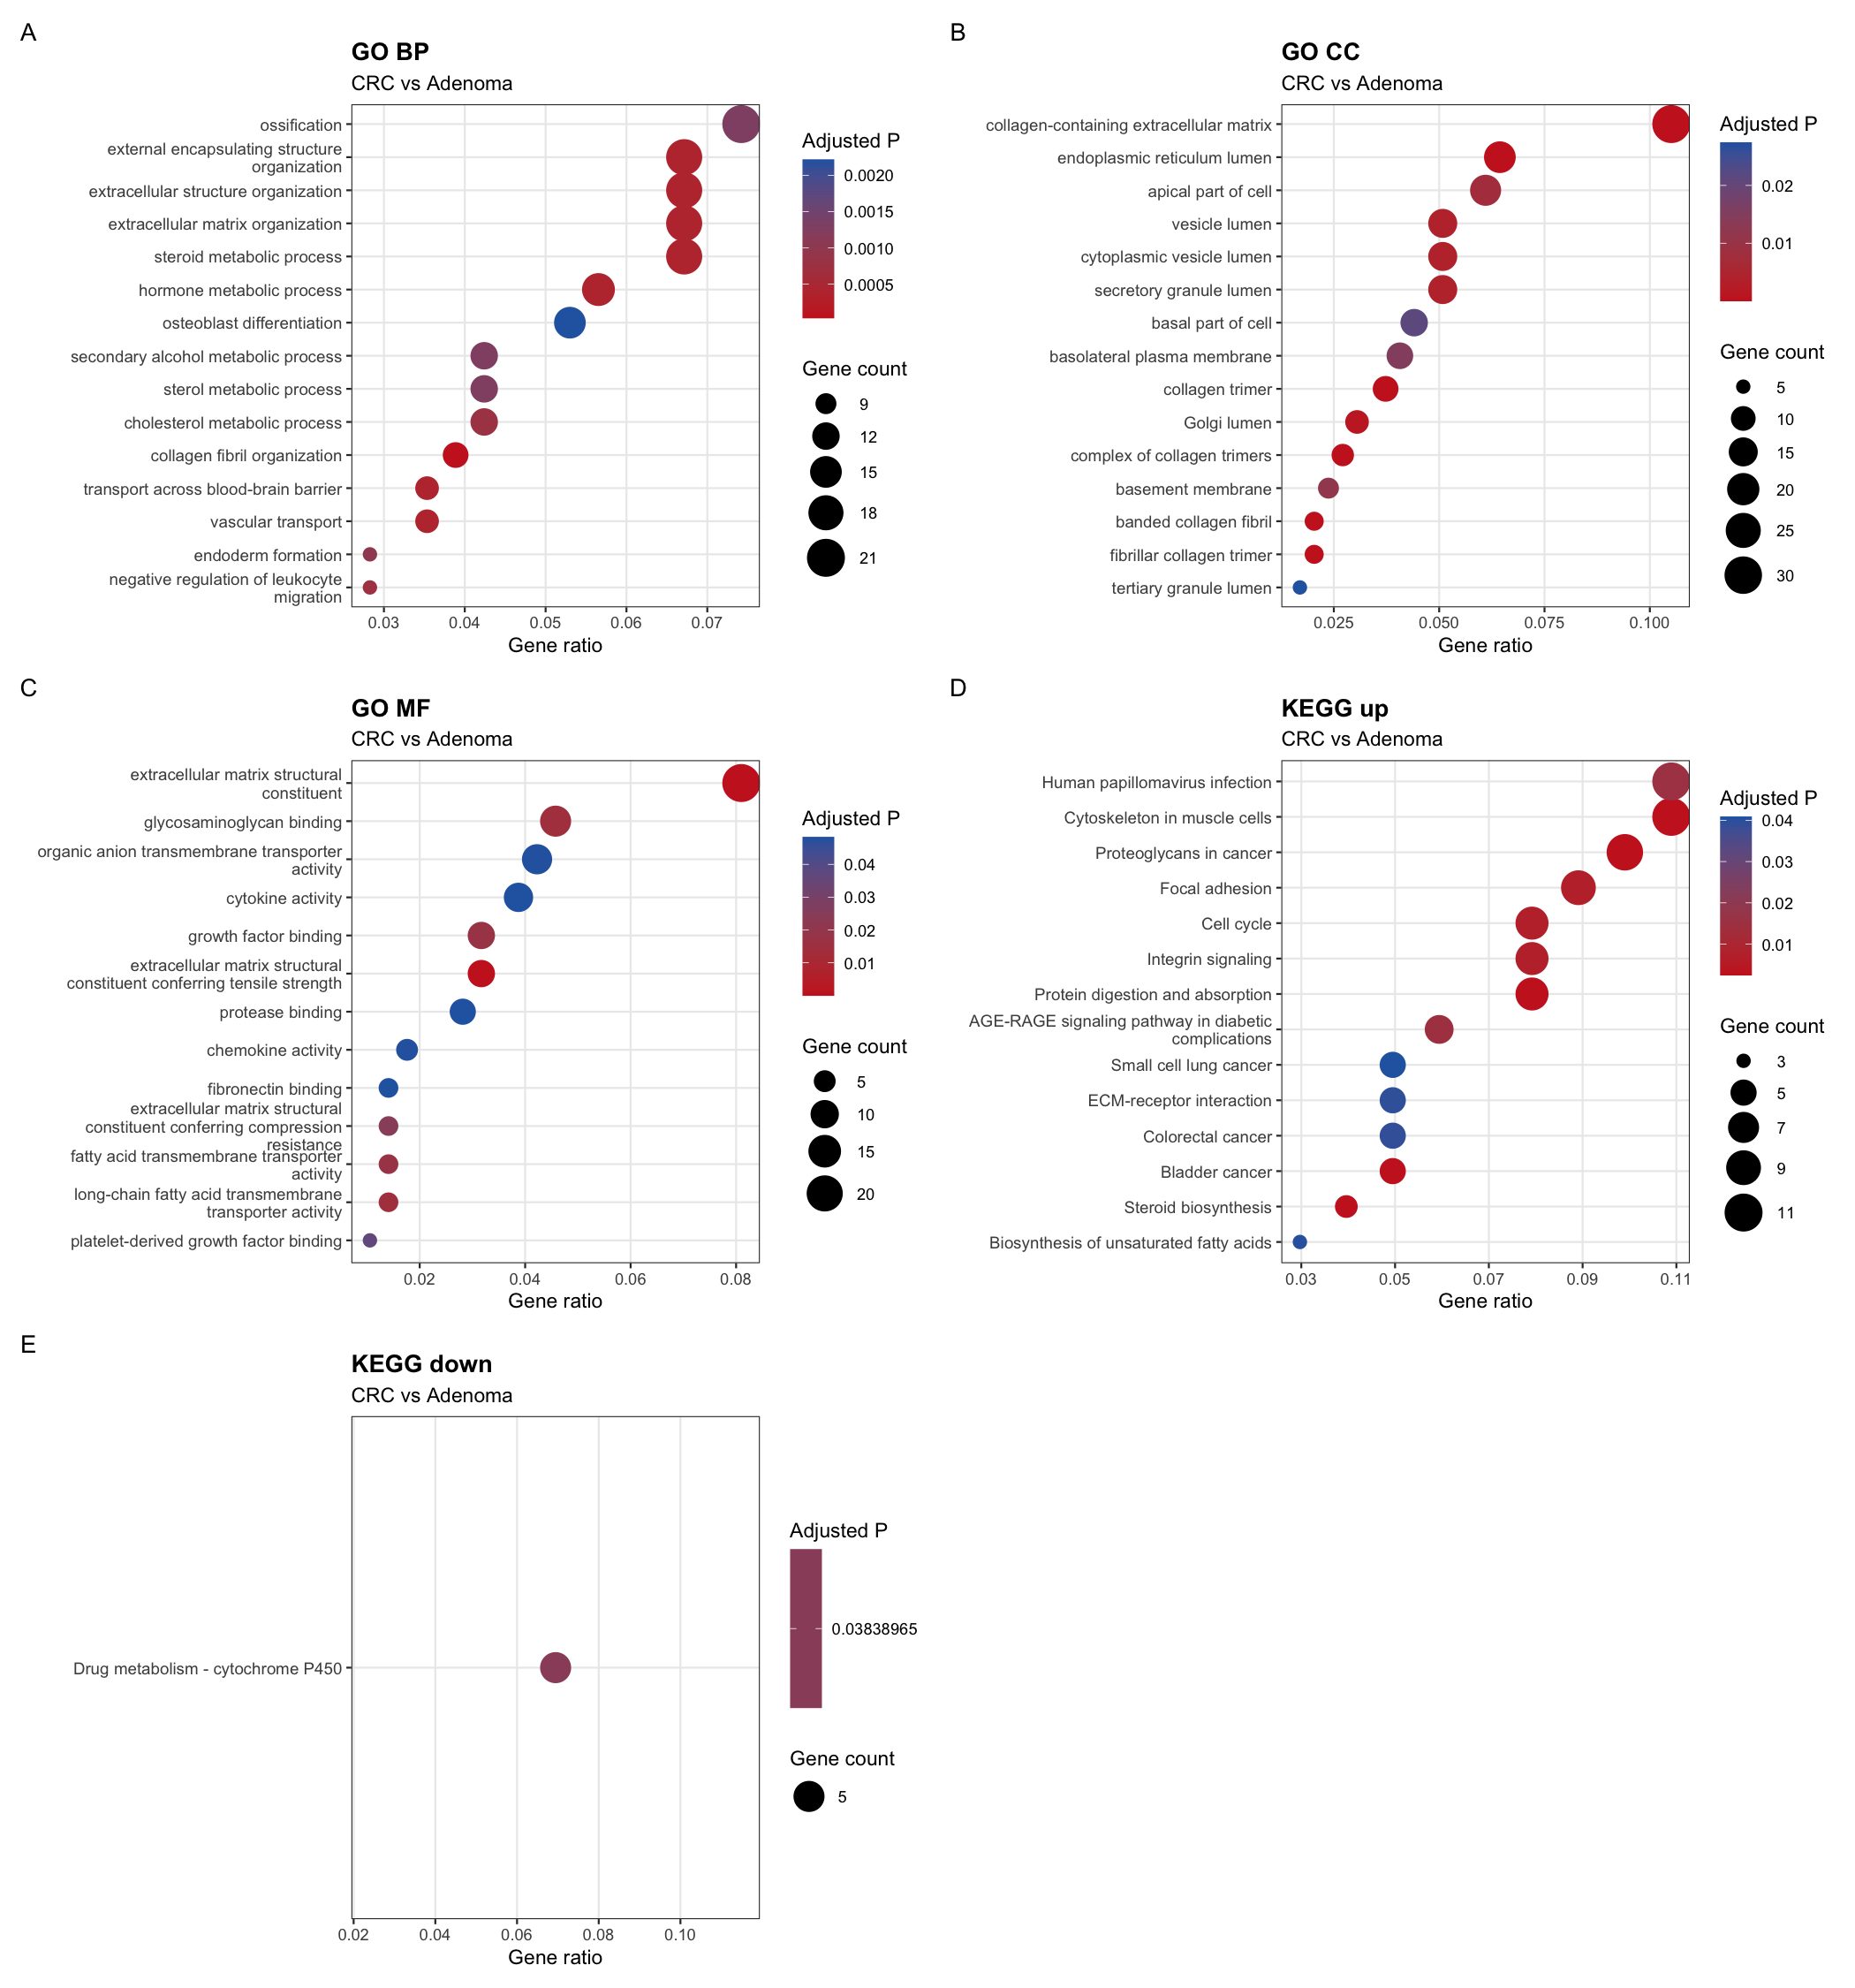

In [14]:
options(repr.plot.width = 14, repr.plot.height = 15)
plot_enrichment("CRC_vs_Adenoma")

<a id="protein-network"></a>
## Protein network
I use the archived STRING edges to examine connections among the progression-associated proteins. The Python script recalculates network centrality and checks the observed compound-disease distances against the saved results. The protein network contains 29 nodes and 61 edges.

In [15]:
network_log <- system2(python, c("scripts/python/network_analysis.py", "--mode", "validate"),
                        stdout = TRUE, stderr = TRUE)
if (!is.null(attr(network_log, "status"))) stop(paste(network_log, collapse = "\n"))
nodes <- read.csv("results/network/ppi_centrality_recalculated.csv")
show_table(head(nodes[, c("name", "degree", "betweenness", "closeness")], 10),
           "Ten highest-degree proteins")

name,degree,betweenness,closeness
MYC,13,0.298,0.657
CXCL8,13,0.261,0.657
GPT,8,0.096,0.590
UGT1A10,8,0.051,0.561
PPARGC1A,8,0.036,0.548
ADH1C,7,0.136,0.469
TNFRSF17,7,0.083,0.511
FABP2,6,0.102,0.523
CXCL2,6,0.055,0.535
HSD17B2,6,0.030,0.523


### Progression-associated protein network
In Figure 5A, node size and color both follow degree. The layout separates the small disconnected components from the main component.

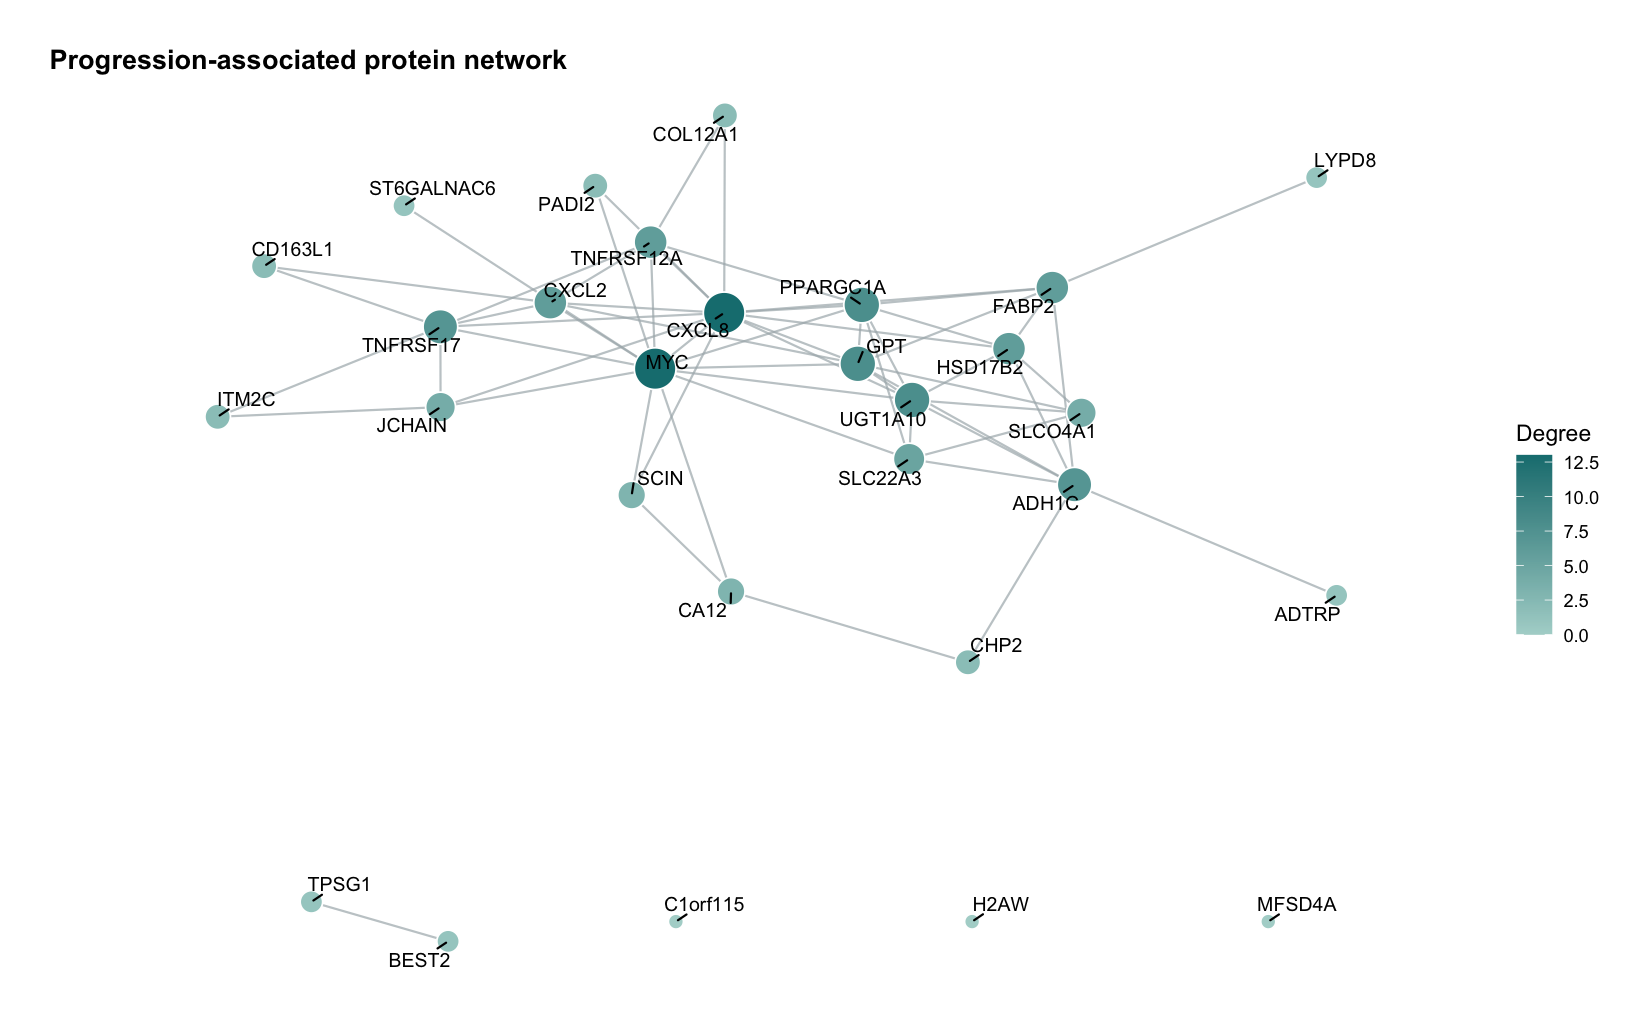

In [16]:
options(repr.plot.width = 11, repr.plot.height = 6.8)
positions <- read.csv("results/network/ppi_layout.csv")
nodes <- merge(nodes, positions, by = "name", sort = FALSE)
edges <- read.delim("data/network/string_interactions_short.tsv", check.names = FALSE)
a <- match(edges[[1]], nodes$name)
b <- match(edges[[2]], nodes$name)
segments <- data.frame(x = nodes$x[a], y = nodes$y[a], xend = nodes$x[b], yend = nodes$y[b])
network <- ggplot() +
  geom_segment(data = segments, aes(x, y, xend = xend, yend = yend),
                color = "#AAB4B8", linewidth = 0.5, alpha = 0.7) +
  geom_point(data = nodes, aes(x, y, size = degree, fill = degree),
              shape = 21, color = "white", stroke = 0.6) +
  geom_text_repel(data = nodes, aes(x, y, label = name), seed = 2026,
                   size = 3.3, max.overlaps = Inf, min.segment.length = 0, box.padding = 0.3) +
  scale_fill_gradient(low = "#AFD5D0", high = "#157D80") +
  scale_size_continuous(range = c(3, 9), guide = "none") +
  scale_x_continuous(expand = expansion(mult = 0.15)) +
  labs(title = "Progression-associated protein network", fill = "Degree") +
  coord_cartesian(clip = "off") + theme_void(base_size = 11) +
  theme(plot.title = element_text(face = "bold", size = 13),
         plot.margin = margin(18, 24, 18, 24))
network

### Protein centrality
I compare degree, betweenness and closeness for the ten highest-degree proteins. Degree counts direct connections; betweenness and closeness describe each protein's position within its connected component.

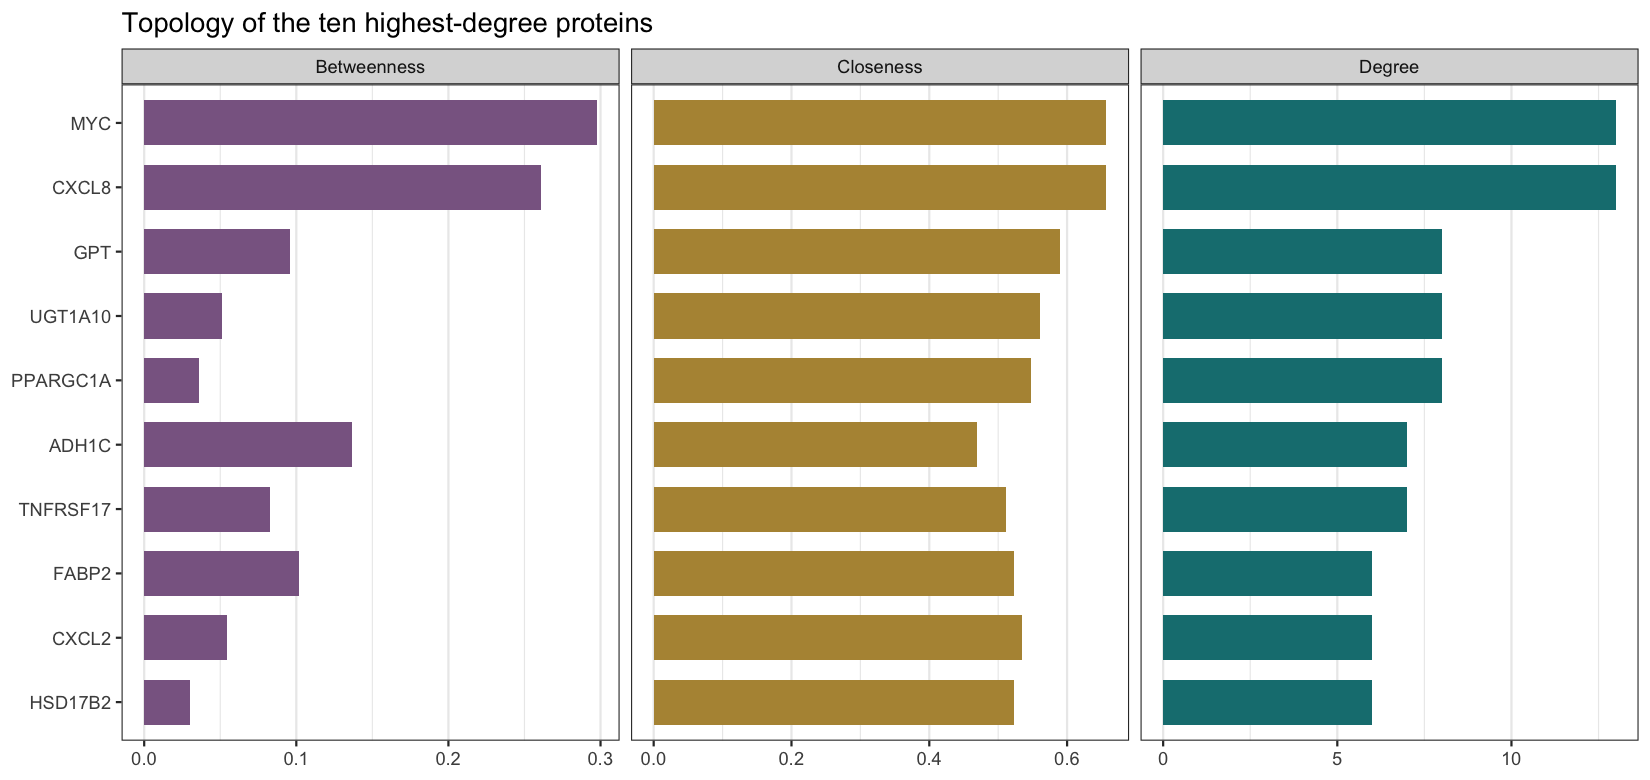

In [17]:
options(repr.plot.width = 11, repr.plot.height = 5.2)
top <- nodes[order(-nodes$degree, -nodes$betweenness, nodes$name), ][1:10, ]
metrics <- rbind(data.frame(name = top$name, metric = "Degree", value = top$degree),
                 data.frame(name = top$name, metric = "Betweenness", value = top$betweenness),
                 data.frame(name = top$name, metric = "Closeness", value = top$closeness))
metrics$name <- factor(metrics$name, levels = rev(top$name))
centrality <- ggplot(metrics, aes(value, name, fill = metric)) +
  geom_col(width = 0.7) + facet_wrap(~metric, scales = "free_x", nrow = 1) +
  scale_fill_manual(values = c(Betweenness = "#8A6792", Closeness = "#B49342", Degree = "#157D80")) +
  labs(title = "Topology of the ten highest-degree proteins", x = NULL, y = NULL) +
  theme_bw(base_size = 11) +
  theme(legend.position = "none", panel.grid.major.y = element_blank())
centrality

<a id="polyphenol-prioritization"></a>
## Polyphenol prioritization
I examine the proximity between compound targets and disease proteins in the archived human interactome. The expression analysis above retains 29 genes, and the archived proximity calculation maps 24 disease nodes into that interactome. I recalculate the observed distances and recover the historical Z scores from the saved null-distribution means and standard deviations.

### Proximity across the compound records
Figure 6A shows the closest-distance Z scores for all 66 recorded entries. The dashed lines mark Z = -1.96 and Z = 1.96.

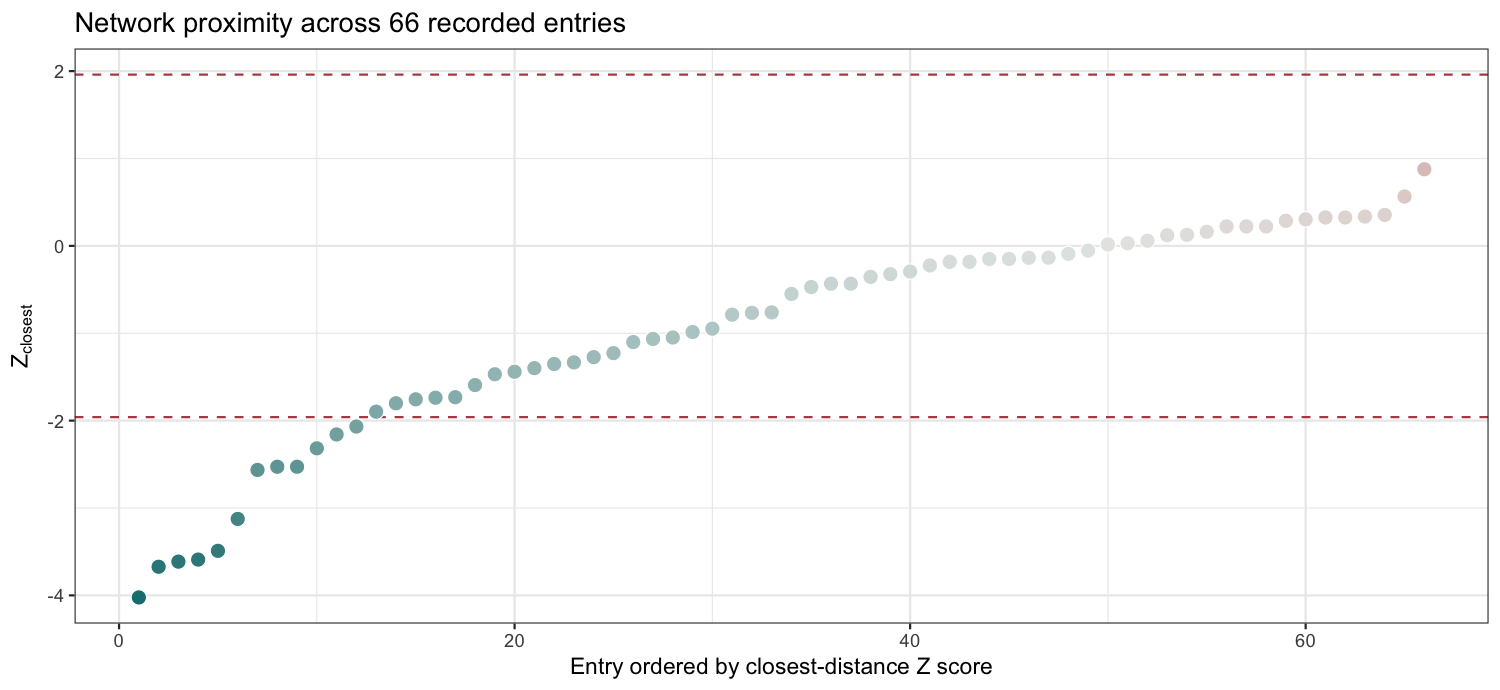

In [18]:
options(repr.plot.width = 10, repr.plot.height = 4.6)
all_records <- read.csv("results/network/proximity_all_66_records.csv")
all_records <- all_records[order(all_records$z_closest), ]
all_records$record_rank <- seq_len(nrow(all_records))
distribution <- ggplot(all_records, aes(record_rank, z_closest)) +
  geom_hline(yintercept = c(-1.96, 1.96), color = "#B34C50", linetype = "dashed") +
  geom_point(aes(fill = z_closest), shape = 21, size = 3.2, color = "white", stroke = 0.4) +
  scale_fill_gradient2(low = "#157D80", mid = "#E5E8E6", high = "#B34C50", midpoint = 0) +
  labs(title = "Network proximity across 66 recorded entries",
       x = "Entry ordered by closest-distance Z score", y = expression(Z[closest])) +
  theme_bw(base_size = 11) + theme(legend.position = "none")
distribution

### The ten highest-ranked compounds
The 66 recorded names correspond to 65 PubChem identities. Eleven identities fall below Z = -1.96. I rank the unique identities by the closest-distance Z score and retain the first ten.

In [19]:
top10 <- read.csv("results/network/top10_candidates.csv")
show_table(top10[, c("rank", "display_name", "pubchem_cid", "z_closest", "n_mapped_chemical")],
           "Ten prioritized compounds")

rank,display_name,pubchem_cid,z_closest,n_mapped_chemical
1,kaempferol,5280863,-4.023,37
2,4-methylcatechol,9958,-3.672,2
3,quercetin,5280343,-3.614,216
4,punicalagin,16129869,-3.590,1
5,umbelliferone,5281426,-3.490,3
6,esculetin,5281416,-3.125,1
7,"2,3-dihydroxybenzoic acid",19,-2.564,1
8,trans-resveratrol,445154,-2.528,63
9,"1,4-naphthoquinone",8530,-2.317,4
10,phloretin,4788,-2.158,2


Kaempferol is the highest-ranked compound. In Figure 6B, the horizontal position gives -Z, and the point size gives the number of mapped targets. The labels retain the signed Z scores.

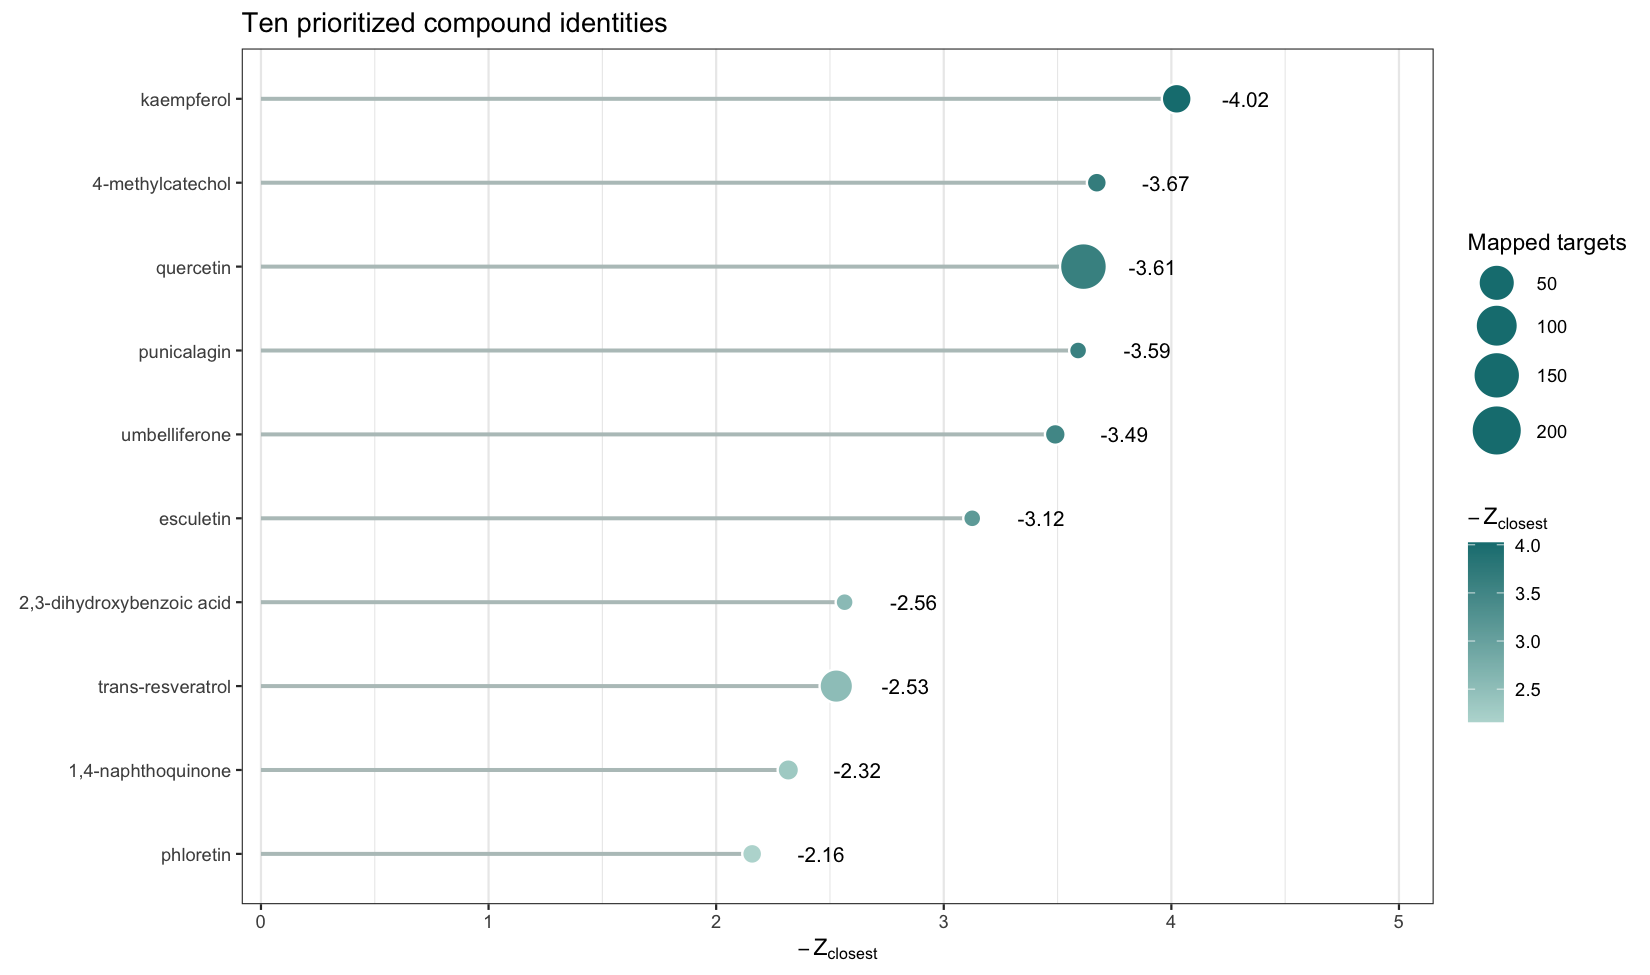

In [20]:
options(repr.plot.width = 11, repr.plot.height = 6.5)
top10 <- read.csv("results/network/top10_candidates.csv")
top10$display_name <- factor(top10$display_name, levels = rev(top10$display_name))
lollipop <- ggplot(top10, aes(-z_closest, display_name)) +
  geom_segment(aes(xend = 0, yend = display_name), linewidth = 0.9, color = "#B7C4C3") +
  geom_point(aes(size = n_mapped_chemical, fill = -z_closest),
              shape = 21, color = "white", stroke = 0.8) +
  geom_text(aes(label = sprintf("%.2f", z_closest)), nudge_x = 0.2, hjust = 0, size = 3.5) +
  scale_size_continuous(range = c(3.5, 10), name = "Mapped targets",
                        guide = guide_legend(override.aes = list(fill = "#157D80", color = "#157D80"))) +
  scale_fill_gradient(low = "#B9DAD5", high = "#157D80", name = expression(-Z[closest])) +
  scale_x_continuous(expand = expansion(mult = c(0.02, 0.22))) +
  labs(title = "Ten prioritized compound identities", x = expression(-Z[closest]), y = NULL) +
  theme_bw(base_size = 11) + theme(panel.grid.major.y = element_blank())
lollipop

### Chemical structures
I use the PubChem identifiers to assemble Figure 7 from the cached chemical depictions. This step runs the [structure-assembly script](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/scripts/build_chemical_structures.py) and displays the image it creates.

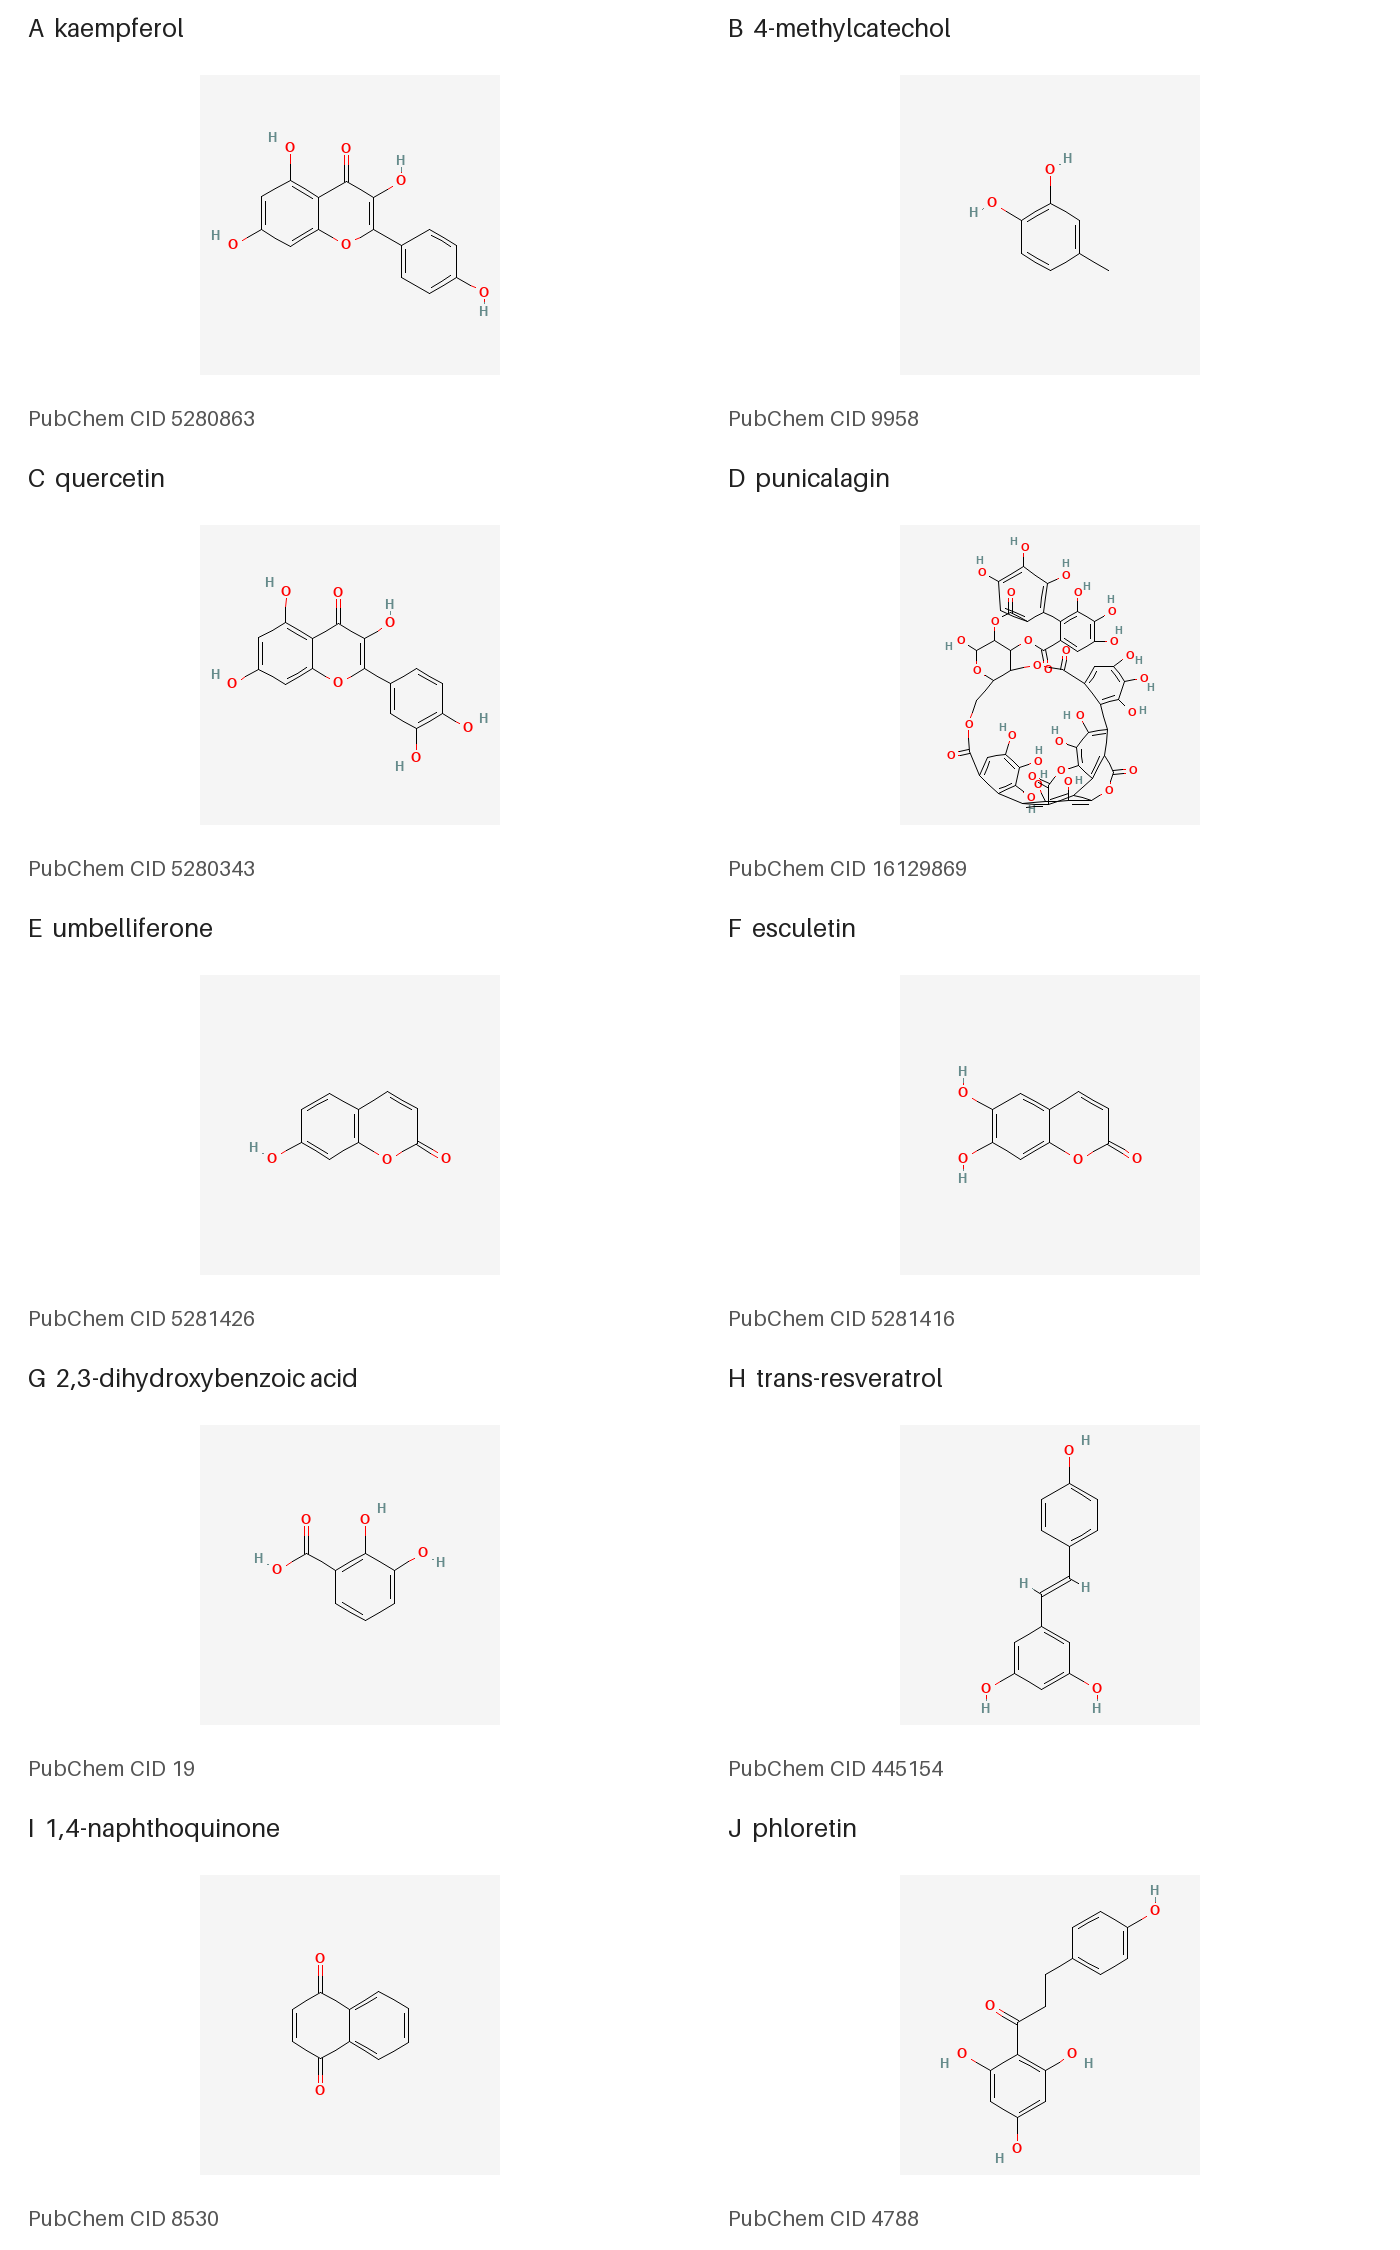

In [21]:
candidates <- read.csv("results/network/top10_candidates.csv")
structure_files <- file.path("data/chemistry/pubchem", paste0("CID_", candidates$pubchem_cid, ".png"))
stopifnot(all(file.exists(structure_files)))
chemistry_log <- system2(python, "scripts/build_chemical_structures.py", stdout = TRUE, stderr = TRUE)
if (!is.null(attr(chemistry_log, "status"))) stop(paste(chemistry_log, collapse = "\n"))
IRdisplay::display_png(file = "figures/reproduced/chemistry/figure_07_compound_structures.png")

### Compound target networks
I use cached human STRING 12.0 responses to reconstruct associations among each compound's recorded targets. The query uses functional associations, a combined score cutoff of 0.400, and no added neighbors. The table shows how many recorded targets map to STRING and how many edges pass the cutoff.

In [22]:
string_log <- system2(python, c("scripts/python/fetch_string_compounds.py", "--offline"),
                       stdout = TRUE, stderr = TRUE)
if (!is.null(attr(string_log, "status"))) stop(paste(string_log, collapse = "\n"))
layouts <- read.csv("results/network/compound_string_layouts.csv")
compound_info <- read.csv("results/network/compound_string_summary.csv")
show_table(compound_info[, c("display_name", "recorded_targets", "string_mapped_nodes", "edges_score_ge_0_4")],
           "Compound target mapping and network sizes")

display_name,recorded_targets,string_mapped_nodes,edges_score_ge_0_4
kaempferol,40,38,161
4-methylcatechol,2,2,0
quercetin,222,215,1560
punicalagin,1,1,0
umbelliferone,3,3,1
esculetin,1,1,0
"2,3-dihydroxybenzoic acid",1,1,0
trans-resveratrol,64,61,232
"1,4-naphthoquinone",4,4,1
phloretin,2,2,1


I join each cached edge list to its node coordinates before plotting. This keeps the network panels aligned with the saved query responses.

In [23]:
compound_edges <- list()
for (i in seq_len(nrow(compound_info))) {
  item <- compound_info[i, ]
  dat <- read.delim(item$edges_file, check.names = FALSE)
  pos <- layouts[layouts$chemical == item$chemical, ]
  dat <- dat[dat$stringId_A %in% pos$string_id & dat$stringId_B %in% pos$string_id, ]
  if (nrow(dat)) {
    ai <- match(dat$stringId_A, pos$string_id)
    bi <- match(dat$stringId_B, pos$string_id)
    compound_edges[[i]] <- data.frame(chemical = item$chemical,
                                     x = pos$x[ai], y = pos$y[ai],
                                     xend = pos$x[bi], yend = pos$y[bi])
  }
}
segment_data <- do.call(rbind, compound_edges)
labels <- setNames(paste0(LETTERS[seq_len(nrow(compound_info))], ". ",
                          compound_info$display_name), compound_info$chemical)
layouts$chemical <- factor(layouts$chemical, levels = compound_info$chemical)
segment_data$chemical <- factor(segment_data$chemical, levels = compound_info$chemical)

Figure 8 displays the reconstructed target networks. A single mapped target remains as an isolated node when the cached response contains no within-target edges.

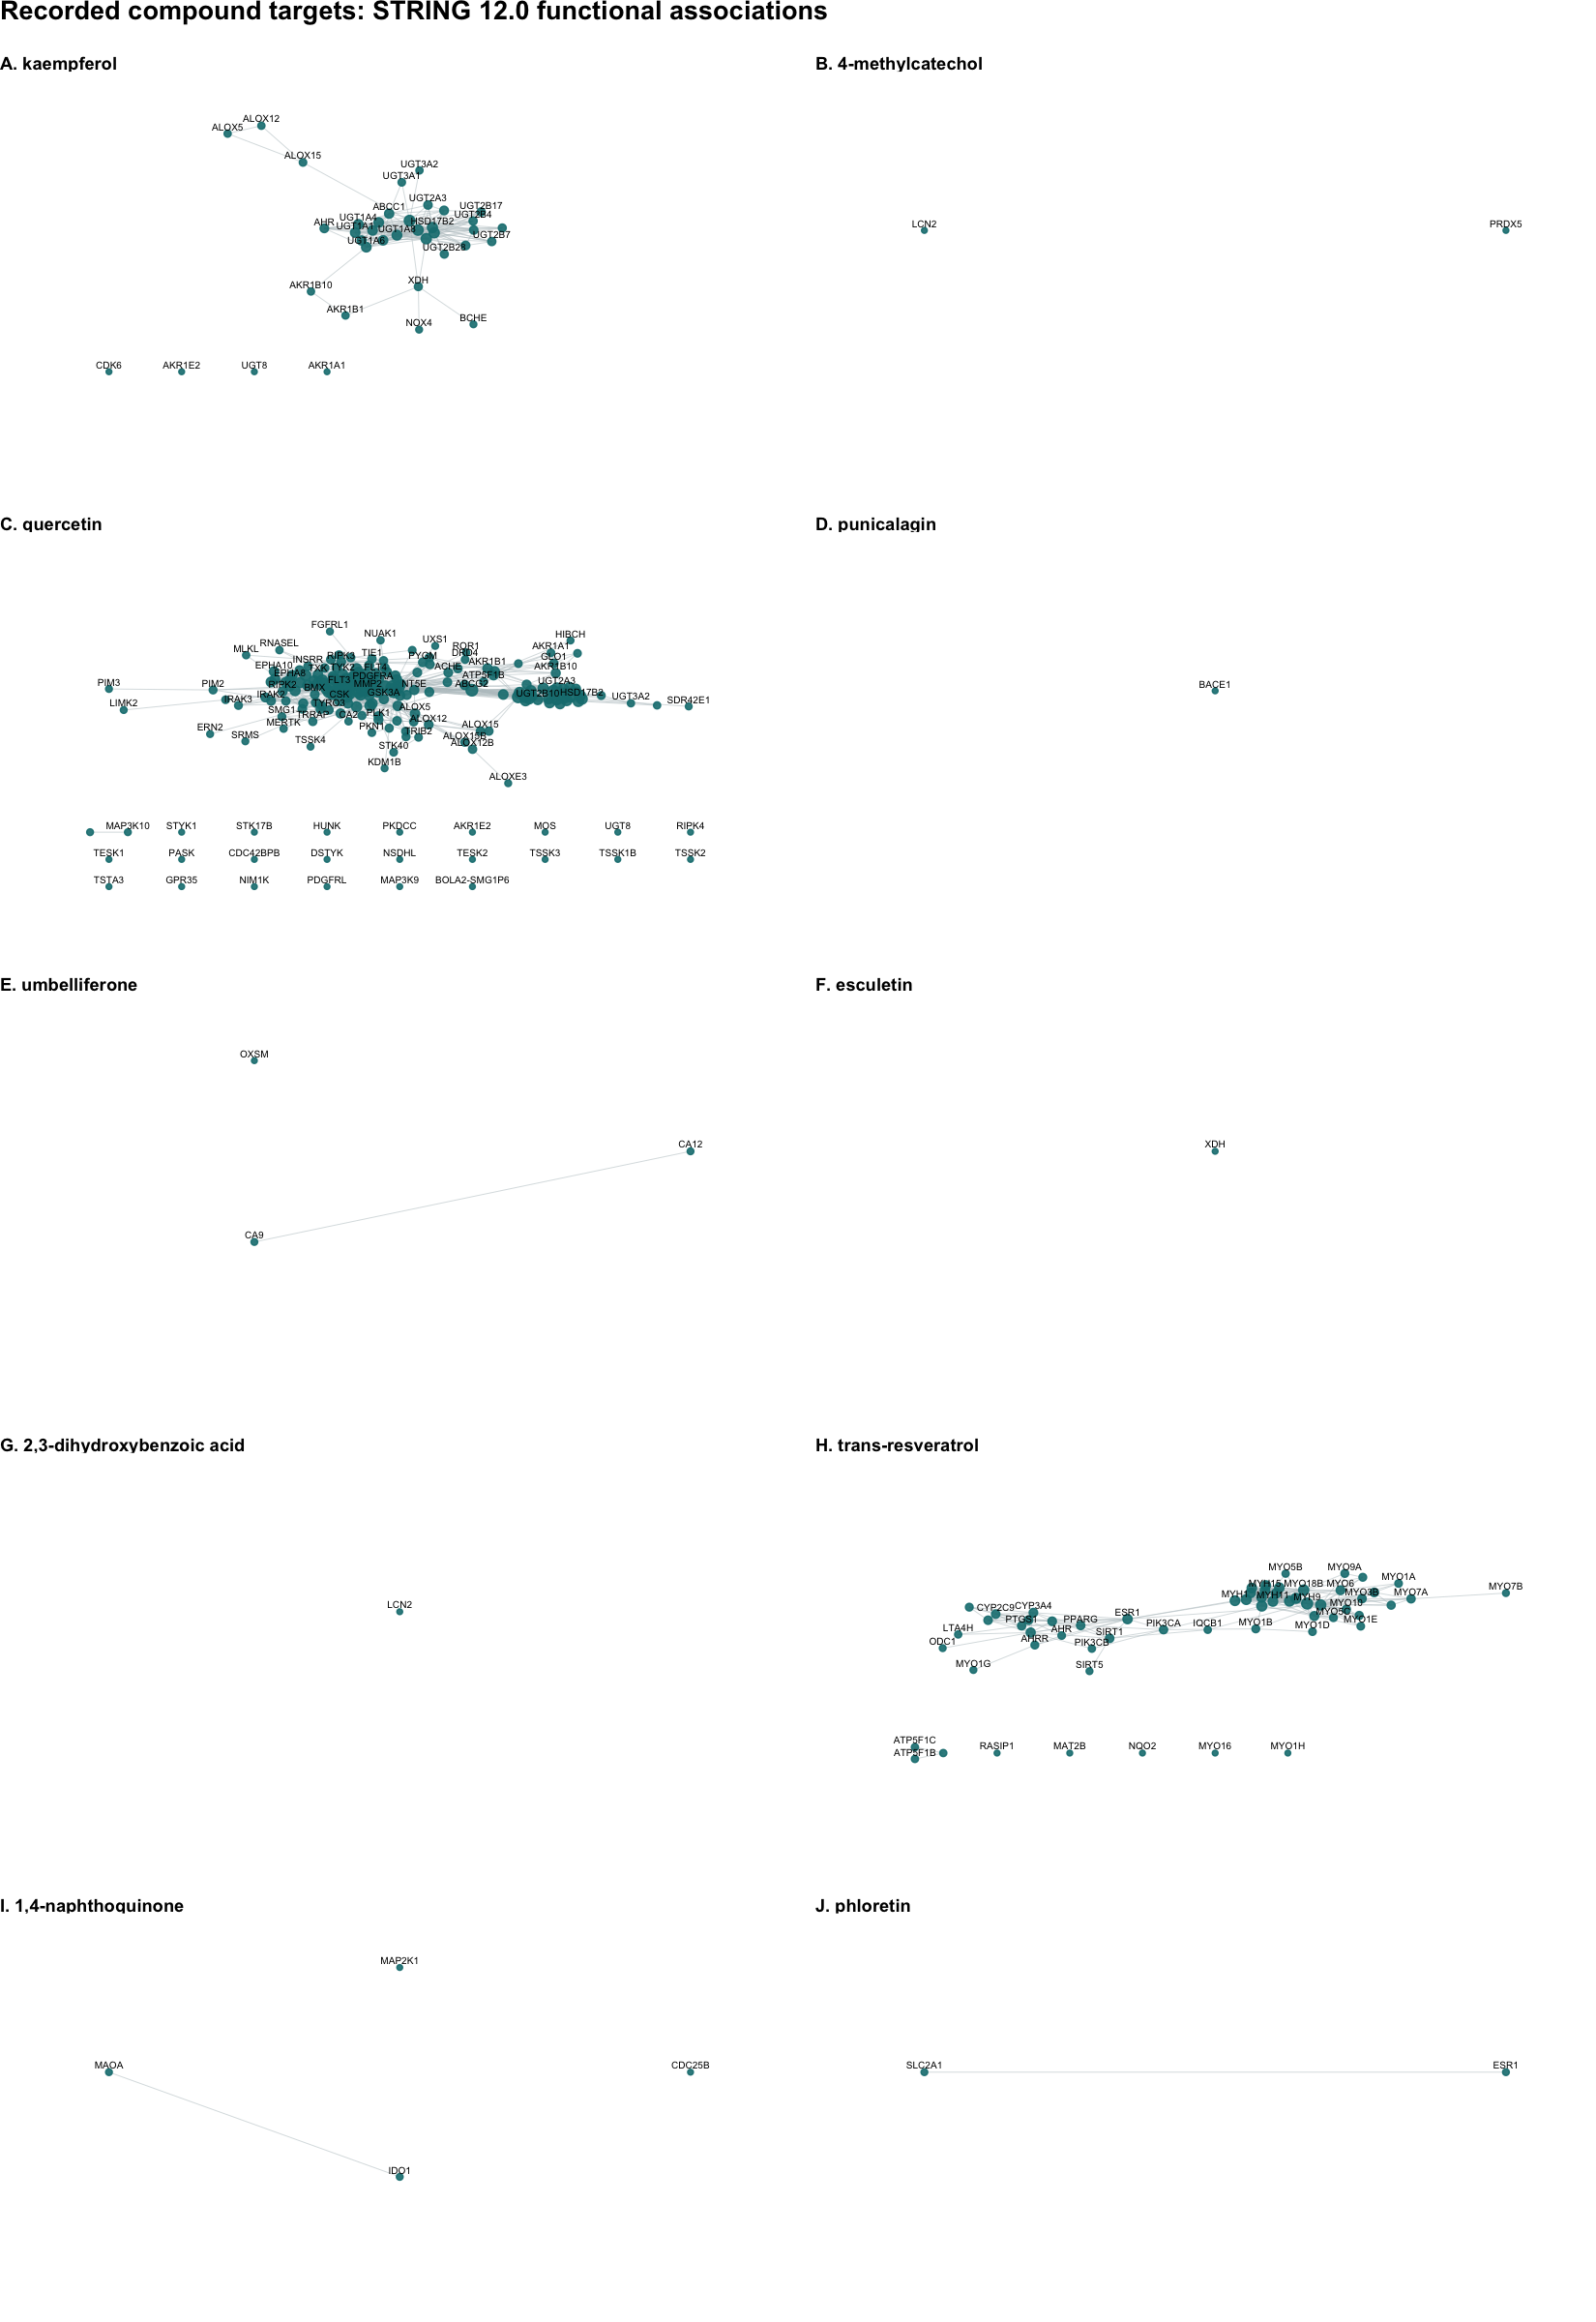

In [24]:
options(repr.plot.width = 11, repr.plot.height = 16)
compound_plot <- ggplot() +
  geom_segment(data = segment_data, aes(x, y, xend = xend, yend = yend),
                color = "#BAC5C8", linewidth = 0.22, alpha = 0.55) +
  geom_point(data = layouts, aes(x, y, size = degree), color = "#157D80", alpha = 0.9) +
  geom_text(data = layouts, aes(x, y, label = symbol), size = 1.7, vjust = -0.55,
             check_overlap = TRUE) +
  facet_wrap(~chemical, ncol = 2, labeller = labeller(chemical = labels)) +
  scale_size_continuous(range = c(1, 3)) +
  scale_x_continuous(expand = expansion(mult = 0.15)) +
  scale_y_continuous(expand = expansion(mult = 0.18)) +
  labs(title = "Recorded compound targets: STRING 12.0 functional associations") +
  theme_void(base_size = 11) +
  theme(legend.position = "none", strip.text = element_text(hjust = 0, face = "bold"),
         panel.spacing = grid::unit(1.2, "lines"),
         plot.title = element_text(size = 13, face = "bold", margin = margin(b = 15)))
compound_plot

<a id="docking"></a>
## Docking
The original workbook contains scores for ten primary compounds and one supplementary punicalagin structure against ADH1C (1HT0) and the CXCL8-Fab receptor system (6WZM). I read those records directly to rebuild Table 5.

In [25]:
docking <- run_docking(root)
show_table(docking$scores[, c("compound", "pubchem_cid", "record_type", "ADH1C_1HT0", "CXCL8_Fab_6WZM")],
           "Table 5. Archived best-mode AutoDock Vina scores (kcal/mol)", digits = 1)

Docking records rebuilt: 10 primary records + 1 supplementary structure, 22 scores.



compound,pubchem_cid,record_type,ADH1C_1HT0,CXCL8_Fab_6WZM
Kaempferol,5280863,primary,-8.3,-5.7
4-Methylcatechol,9958,primary,-5.5,-4.7
Quercetin,5280343,primary,-8.2,-5.6
Punicalagin,16129869,primary,-6.3,-2.6
Umbelliferone,5281426,primary,-6.5,-5.5
Esculetin,5281416,primary,-6.6,-5.6
"2,3-Dihydroxybenzoic acid",19,primary,-5.9,-4.7
Trans-resveratrol,445154,primary,-7.7,-5.9
"1,4-Naphthoquinone",8530,primary,-7.0,-5.5
Phloretin,4788,primary,-8.1,-6.1


### Comparing the archived scores
I plot both receptor systems on the same score scale. The supplementary punicalagin structure is marked separately, and the recorded positive score is retained.

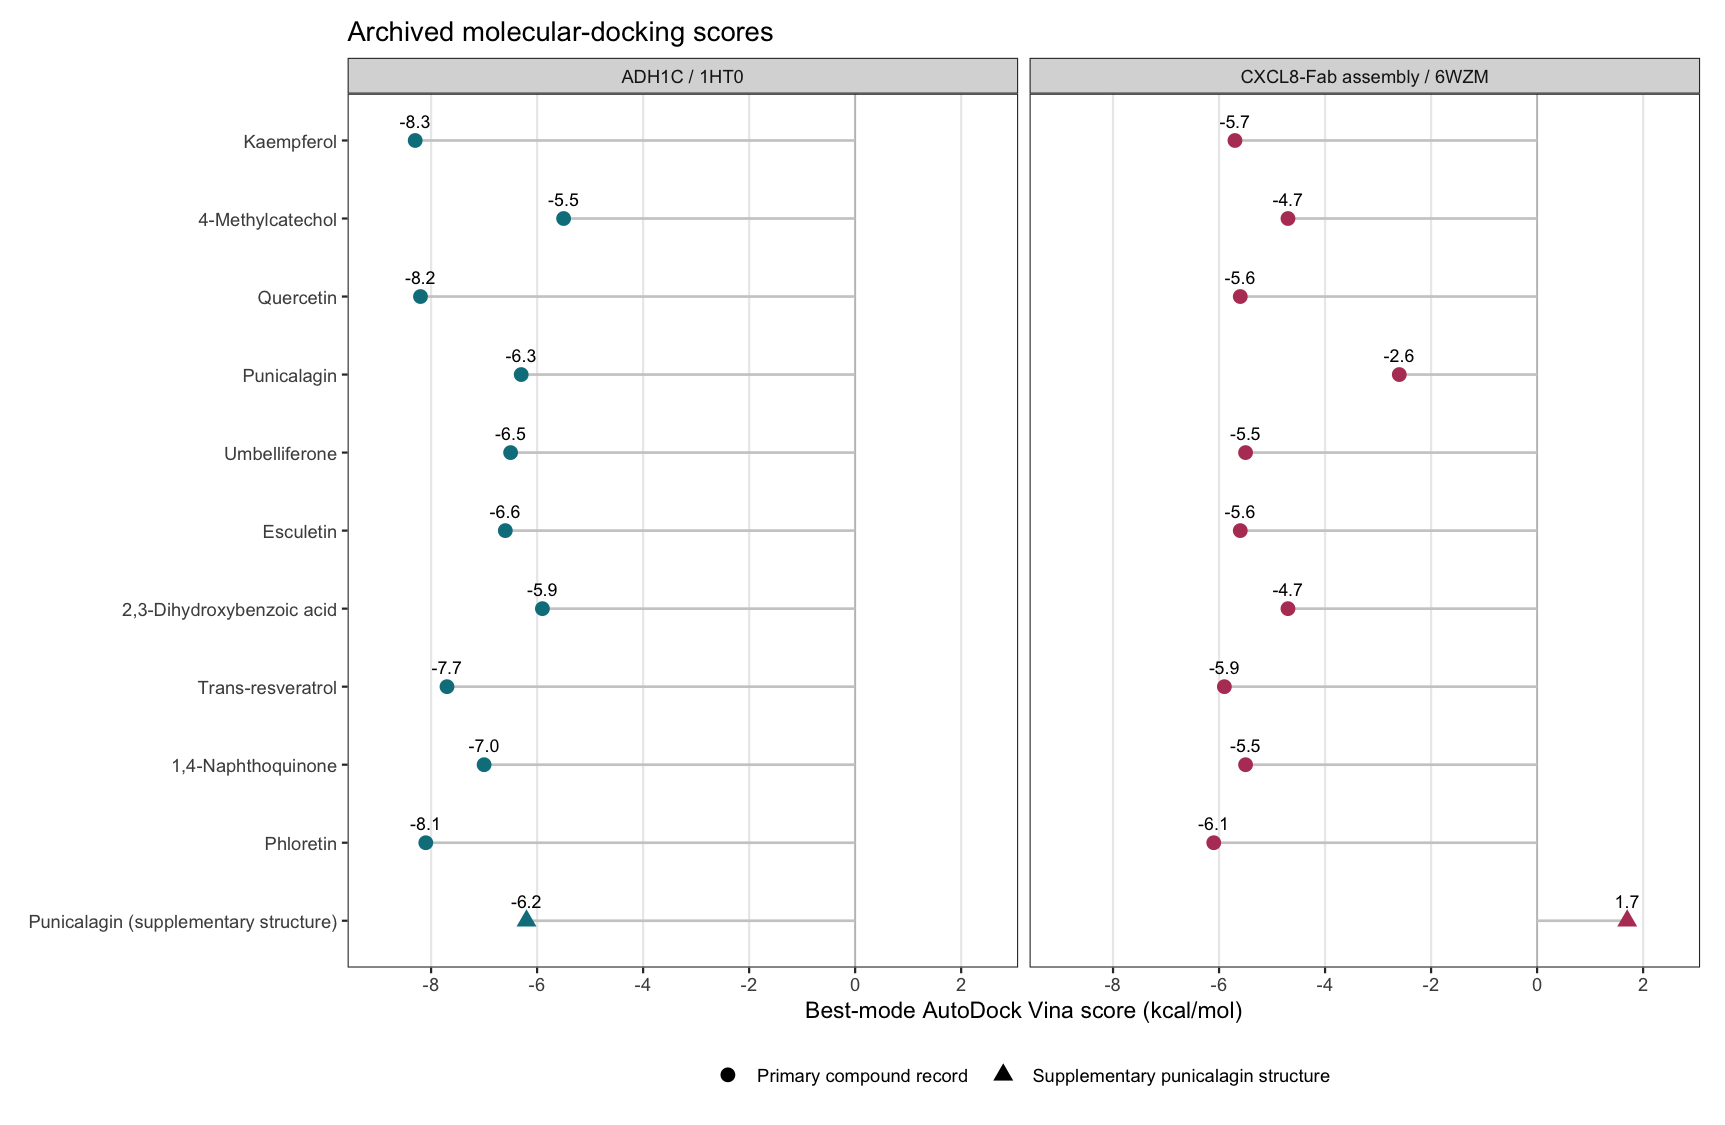

In [26]:
options(repr.plot.width = 11.5, repr.plot.height = 7.5)
records <- docking$scores
score_data <- rbind(
  data.frame(records, receptor = "ADH1C / 1HT0", score = records$ADH1C_1HT0),
  data.frame(records, receptor = "CXCL8-Fab assembly / 6WZM", score = records$CXCL8_Fab_6WZM)
)
score_data$compound <- factor(score_data$compound, levels = rev(records$compound))
score_data$receptor <- factor(score_data$receptor,
                               levels = c("ADH1C / 1HT0", "CXCL8-Fab assembly / 6WZM"))
score_plot <- ggplot(score_data, aes(score, compound)) +
  geom_vline(xintercept = 0, color = "grey75", linewidth = 0.4) +
  geom_segment(aes(x = 0, xend = score, yend = compound), color = "grey80", linewidth = 0.6) +
  geom_point(aes(color = receptor, shape = record_type), size = 3) +
  geom_text(aes(label = sprintf("%.1f", score)), nudge_y = 0.25, size = 3, show.legend = FALSE) +
  facet_grid(. ~ receptor) +
  scale_color_manual(values = c("#087F8C", "#B74065"), guide = "none") +
  scale_shape_manual(values = c(primary = 16, supplementary_structure = 17),
                      labels = c("Primary compound record", "Supplementary punicalagin structure"), name = NULL) +
  scale_x_continuous(limits = c(-9, 2.5), breaks = seq(-8, 2, 2)) +
  labs(title = "Archived molecular-docking scores",
       x = "Best-mode AutoDock Vina score (kcal/mol)", y = NULL) +
  theme_bw(base_size = 11) +
  theme(panel.grid.major.y = element_blank(), panel.grid.minor = element_blank(),
         legend.position = "bottom", plot.margin = margin(10, 12, 10, 10))
score_plot

### Representative docking poses
Figure 9 is the illustration from my submitted manuscript: phloretin in the 6WZM receptor system and kaempferol in 1HT0. The cell displays that preserved illustration. The [docking record](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/docs/docking-provenance.md) lists the prepared inputs and pose coordinates needed for a new Vina search.

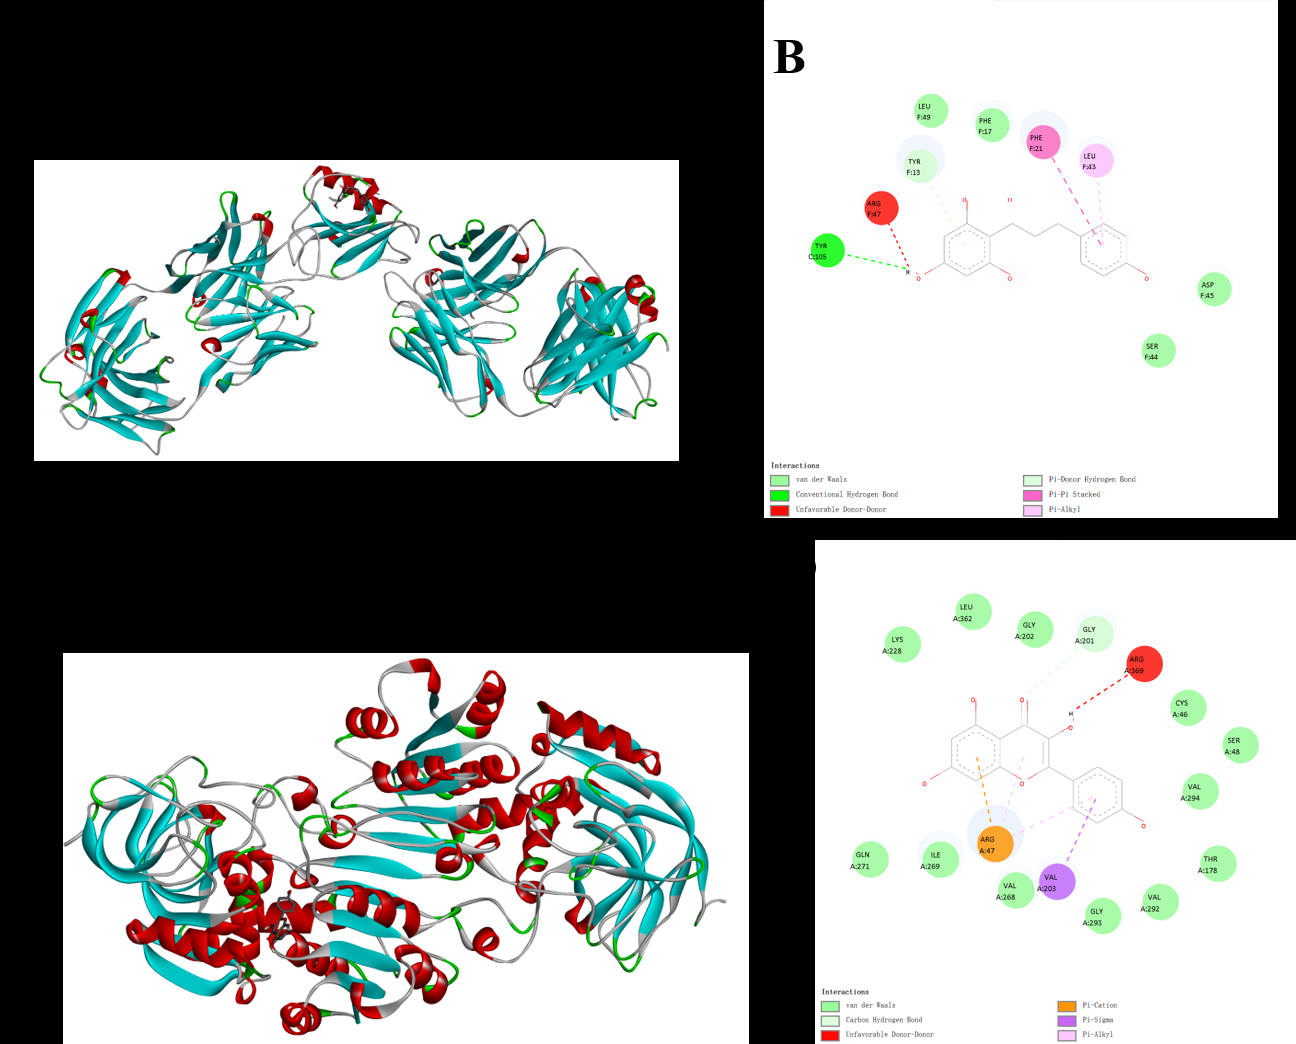

In [27]:
pose_figure <- "figures/submitted/figure_09.png"
stopifnot(file.exists(pose_figure))
IRdisplay::display_png(file = pose_figure)

<a id="checks-and-references"></a>
## Checks against the archived results
I compare the expression results with the archived differential-expression tables and check the identities of the 29 progression-associated genes. The existing analysis module also writes the complete result tables to `results/transcriptomics/`.

In [28]:
transcriptomics <- run_transcriptomics(root)
stopifnot(identical(de_summary, transcriptomics$summary),
          setequal(prog$gene, transcriptomics$progressive$gene))
show_table(read.csv("results/transcriptomics/verification.csv"), "Expression checks", digits = 15)
show_table(read.csv("results/enrichment/verification.csv"), "Enrichment table checks")

Transcriptomics complete: 725 / 312 / 1544 DEGs; 8 up + 21 down progression-associated genes.



check,passed,max_absolute_error
Adenoma_vs_Normal_saved_DEG_table,TRUE,5e-15
CRC_vs_Adenoma_saved_DEG_table,TRUE,5e-15
CRC_vs_Normal_saved_DEG_table,TRUE,5e-15
29_progressive_gene_identities,TRUE,0e+00


check,passed,expected_tested,expected_significant
Adenoma_vs_Normal__GO_BP,TRUE,4540,239
Adenoma_vs_Normal__GO_CC,TRUE,381,21
Adenoma_vs_Normal__GO_MF,TRUE,766,68
Adenoma_vs_Normal__KEGG_up,TRUE,211,10
Adenoma_vs_Normal__KEGG_down,TRUE,283,7
CRC_vs_Adenoma__GO_BP,TRUE,3394,93
CRC_vs_Adenoma__GO_CC,TRUE,322,19
CRC_vs_Adenoma__GO_MF,TRUE,563,13
CRC_vs_Adenoma__KEGG_up,TRUE,180,14
CRC_vs_Adenoma__KEGG_down,TRUE,168,1


I also check the SHA-256 hashes of the 196 preserved research inputs. This confirms that the input files still match the repository manifest.

In [29]:
input_checks <- system2(python, "scripts/verify_repository.py", stdout = TRUE, stderr = TRUE)
if (!is.null(attr(input_checks, "status"))) stop(paste(input_checks, collapse = "\n"))
cat(paste(input_checks, collapse = "\n"))

{
  "checked_input_files": 196,
  "checksum_failures": []
}

### Software used in this run
The R session below records the software used to execute these cells. Python package versions are recorded in `environment/requirements.txt` and `environment/requirements-notebook.txt`.

In [30]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: aarch64-apple-darwin20
Running under: macOS 27.0

Matrix products: default
BLAS:   /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/lib/libRblas.0.dylib 
LAPACK: /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.12.0

locale:
[1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Asia/Shanghai
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.0 ggrepel_0.9.6   ggplot2_4.0.2   limma_3.62.2   

loaded via a namespace (and not attached):
 [1] rematch_2.0.0      gtable_0.3.6       jsonlite_2.0.0     dplyr_1.1.4       
 [5] compiler_4.4.3     crayon_1.5.3       tidyselect_1.2.1   Rcpp_1.0.14       
 [9] IRdisplay_1.1      textshaping_1.0.1  systemfonts_1.2.3  scales_1.4.0      
[13] readxl_1.4.5       uuid_1.2-1         fastmap_1.2.0      IRkernel_1.3.2    
[17] statmod_1.

## References and source records

- Expression data: [GEO GSE228012](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE228012), associated with [Lin et al.](https://doi.org/10.1002/advs.202410058).
- Compound-target records and network framework: [do Valle et al. (2021)](https://doi.org/10.1038/s43016-021-00243-7), [upstream code](https://github.com/italodovalle/polyphenols).
- Protein associations: [STRING](https://string-db.org/).
- Chemical identifiers and depictions: [PubChem](https://pubchem.ncbi.nlm.nih.gov/).
- Receptor structures: [PDB 1HT0](https://www.rcsb.org/structure/1HT0) and [PDB 6WZM](https://www.rcsb.org/structure/6WZM).

I assembled this notebook from my project files in November 2026, with Codex assistance for the executable presentation. The [provenance record](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/docs/provenance.md) documents the original files, frozen enrichment results, historical randomization moments and submitted docking illustrations. A fresh seeded network randomization can be run with `scripts/python/network_analysis.py --mode randomize --n-random 1000`.